[![Open In Colab](https://colab.research.google.com/assets/colab/badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_AdversarialRobustness_Ozkaraca2025.ipynb)

# Adversarial robustness of quantum neural networks vs classical models: Ozkaraca (2025) step by step

**Paper.** Gülrana Özkaraca, *Comparing Adversarial Robustness: A study of Quantum Neural Network Architectures vs. Classical AI models*, Zenodo preprint, 2025. https://doi.org/10.5281/zenodo.17511924

**What this notebook does.** The paper asks one question: when an attacker adds a small, carefully chosen perturbation of size `epsilon` to a picture, how fast does a quantum classifier lose accuracy, and is it more robust than a classical one? The paper trains a *variational quantum classifier* (VQC) on MNIST digits 0 versus 1, attacks it with two textbook white-box attacks (**FGSM**, one gradient step, and **PGD**, many small gradient steps) for `epsilon` from 0.01 to 0.4, and reports the accuracy under attack in Table 1 and Figures 3 and 4. Its conclusion also mentions a *quantum support vector machine with a ZZFeatureMap*, and it compares with a CNN and a transformer. In this notebook you will

1. download MNIST (public) and keep only the digits 0 and 1;
2. build the quantum classifiers: a 4-qubit **VQC** (ZZFeatureMap + RealAmplitudes) and a **QSVM** (quantum kernel from the same ZZFeatureMap), as exact state-vector simulators written in PyTorch so that the *attacker can take true gradients*, and **assert that these simulators agree with the Qiskit circuits** that are drawn in the circuit section further down;
3. train classical comparison models on the same data: a small CNN, a tiny Vision Transformer, and (on exactly the same 4 quantum inputs) an MLP, an RBF-SVM and a random forest;
4. run FGSM and PGD at the paper's `epsilon` values against every model, over several random seeds;
5. redraw the paper's Figures 3 and 4 and Table 1 next to our numbers and give a verdict per claim ("reproduced", "not reached", "exceeded", "cannot be checked");
6. read the paper critically (for example why its PGD curve is perfectly flat beyond `epsilon = 0.1`).

**How to run.** Open in Google Colab (CPU runtime is enough), then *Runtime -> Run all*. With `FAST_MODE = True` (default for a class demo) it finishes in about 10 minutes; with `FAST_MODE = False` it uses larger cohorts and more seeds. No account or token is needed: MNIST is a public dataset. (If you ever swap in a *gated* Hugging Face dataset, put your own token in Colab *Secrets* under the name `HF_TOKEN`; the code below reads it from there or from the environment and never prints it.)

**What you get at the end.** Accuracy-versus-epsilon curves for seven models and three attack variants, the paper's Table 1 rebuilt side by side with our values, adversarial example images, confusion matrices, and an honest list of what the paper's numbers can and cannot be compared with.

## The paper in one page

**Problem.** Neural networks are fooled by tiny, crafted perturbations (adversarial examples). Do quantum neural networks (QNNs) resist them better than CNNs and transformers? In a security setting this is the question of whether a quantum classifier is a harder target for an evasion attack.

**Threat model.** White-box evasion at test time: the attacker knows the model and its gradients, and changes the input image by at most `epsilon` per pixel (L-infinity ball). The paper does not say so explicitly; this is the standard FGSM/PGD setting.

**Models.** VQCs (Table 1, Figures 3 and 4); a quantum kernel method (abstract and conclusion: "quantum support vector machine utilizing a ZZFeatureMap"); CNN and transformer baselines (Section 3.1). The conclusion says explicitly that the experiments were "limited to a small binary subset of MNIST and a noiseless simulation environment".

**Data.** MNIST, binary task digit 0 versus digit 1 (Sections 4 and 5.1), normalised to fit quantum encoding ranges.

**Attacks.** FGSM with `epsilon in {0.01, 0.05, 0.1, 0.2, 0.3, 0.4}` and PGD (iterative, projected on the `epsilon` ball); step count, step size and starting point of PGD are not given.

**Reported results (Table 1, VQC, accuracy on the perturbed test set).**

| epsilon | 0.01 | 0.05 | 0.1 | 0.2 | 0.3 | 0.4 |
|---|---|---|---|---|---|---|
| FGSM | 0.9144 | 0.8978 | 0.8748 | 0.8217 | 0.7600 | 0.6931 |
| PGD | 0.8634 | 0.8417 | 0.8119 | 0.8119 | 0.8119 | 0.8119 |

The text adds a clean accuracy of 0.8686 for the PGD experiment, a "near-linear" decline under FGSM, a "sharp drop followed by a plateau beyond epsilon = 0.10" under PGD, the claim that robustness is "attack-dependent", and that QNNs "maintain stability" at epsilon = 0.05 better than a CNN without defense. Table 2 (MNIST/EMNIST with compounded CW+PGD attacks, 92% and 5%) is copied from another paper (Yocam et al., 2024) and uses other models and attacks.

**Not given by the paper.** The circuit (feature map, ansatz, depth, number of qubits), how 784 pixels are reduced to qubits, training budget and optimiser, PGD parameters, CNN and transformer architectures, number of test images, seeds. No code is provided.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | MNIST, digits 0 vs 1 | same; downloaded from the Hugging Face parquet mirror `ylecun/mnist` (OpenML fallback); class-balanced random subsets (`N_TRAIN` train, `N_TEST` test images) drawn per seed |
| Reduction to qubits | not given ("normalized to fit quantum encoding ranges") | `# CHOICE:` 28x28 image -> 7x7 average pooling (16 numbers) -> PCA to `N_QUBITS = 4` components -> min-max scaling to `[0, pi]` (fitted on the training split only); the whole map is linear, so the attacker perturbs the **28x28 pixels** and gradients flow through it |
| Quantum model(s) | "VQC" (Table 1) and "QSVM with ZZFeatureMap" (conclusion) | both: VQC = `zz_feature_map(4, reps=2, entanglement="linear")` + `real_amplitudes(4, reps=3)` (16 trainable angles), prediction = qubit 0 measured in the Z basis (this is what Qiskit's `VQC` does for two classes); QSVM = fidelity kernel of the same ZZFeatureMap + `SVC(kernel="precomputed")` |
| Optimiser | "hybrid quantum-classical optimization" | Adam on exact state-vector gradients (`# CHOICE:`); cross-entropy loss; the angle scale of the encoding (0.25, 0.5 or 1 = feature-map bandwidth) is chosen on a validation split of the training data |
| Simulator | simulated quantum backend, noiseless (conclusion) | exact PyTorch state-vector simulator, asserted equal to the Qiskit circuit (probabilities and kernel entries, and again for every trained model) |
| Attack norm and clipping | not given | L-infinity ball of radius `epsilon`, pixels clipped to `[0, 1]` (`# CHOICE:`) |
| FGSM | one signed-gradient step of size `epsilon` | same |
| PGD | iterative, projected; steps/step size not given | two variants (`# CHOICE:`): **PGD-eps** (10 steps of size `2.5*epsilon/10`, the Madry et al. recipe) and **PGD-fixed** (10 steps of fixed size 0.01, which can never move a pixel by more than 0.1; see the critical reading) |
| Attack loss | cross-entropy | the signed gradient of a binary cross-entropy equals the signed gradient of the (negative, label-signed) decision margin, so we use the margin for all models (same attack direction, no saturation) |
| Classical baselines | CNN and transformer, architectures not given; values not tabulated | small CNN and tiny ViT on the 28x28 pixels; MLP, RBF-SVM and random forest on **exactly the same 4 quantum input angles**; the random forest is not differentiable and is attacked by transfer from the MLP |
| Adversarial training | described in Section 4.2 but no results shown | not done (clean training only); left as an exercise |
| Noise study | mentioned in 5.3 but conclusion says "noiseless" | not done (cannot be checked) |
| Statistics | variance and confidence intervals announced | mean +- std over `N_SEEDS` seeds, each with its own data subset and initialisation |

In [1]:
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
# Pinned to the versions this notebook was tested with (Colab already ships numpy, pandas, scikit-learn, matplotlib, torch).
if IN_COLAB or not all(_have(m) for m in ["qiskit", "pylatexenc", "pyarrow", "huggingface_hub", "PIL", "torch", "sklearn"]):
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "pylatexenc", "pyarrow", "huggingface_hub", "pillow"])
    print("Packages installed. If imports below fail, restart the session (Runtime -> Restart session) and run again.")

In [2]:
import numpy as np
SEED = 42
FAST_MODE = False          # True: about 10 minutes on a CPU (class demo). False: 1000 train / 600 test images and 5 seeds, about 40 minutes on a shared 4-core CPU (the committed copy of this notebook is the FAST_MODE = False run)
IBM_TOKEN = ""              # unused: the paper only uses simulators; no real-hardware cell in this notebook
DATA_DIR = "qml_data"       # downloads and caches live here (never inside a git repo)

DIGITS = (0, 1)             # binary task of the paper: digit 0 (label 0) vs digit 1 (label 1)
N_QUBITS = 4                # CHOICE: the paper does not give it; 4 qubits = 4 PCA angles
POOL_K = 7                  # CHOICE: 7x7 average pooling -> 4x4 = 16 numbers before PCA
FM_REPS, ANSATZ_REPS = 2, 3 # CHOICE: ZZFeatureMap reps=2 (Qiskit default), RealAmplitudes reps=3 (Qiskit default)
VQC_SCALES = [0.25, 0.5, 1.0]         # angle scale (bandwidth) candidates for the VQC encoding, chosen on a validation split of the training data
QSVM_SCALES = [0.25, 0.5, 1.0, 2.0]   # kernel bandwidth candidates (angle scale), chosen on a validation split of the training data
SVM_C = 1.0

EPS_LIST = [0.01, 0.05, 0.1, 0.2, 0.3, 0.4]   # the paper's epsilon grid (Table 1)
PGD_STEPS = 10              # CHOICE: not given by the paper
PGD_ALPHA_FACTOR = 2.5      # PGD-eps: step = 2.5 * eps / steps (Madry et al.)
PGD_ALPHA_FIXED = 0.01      # PGD-fixed: constant step 0.01 -> total reach 10 * 0.01 = 0.1

if FAST_MODE:
    N_TRAIN, N_TEST, N_SEEDS = 300, 200, 2          # images per seed (class balanced)
    VQC_STEPS, VQC_BATCH, VQC_LR = 150, 64, 0.1     # Adam steps for the VQC
    NN_EPOCHS = 6                                    # epochs for MLP / CNN / ViT
else:
    N_TRAIN, N_TEST, N_SEEDS = 1000, 600, 5
    VQC_STEPS, VQC_BATCH, VQC_LR = 300, 64, 0.1
    NN_EPOCHS = 12

# ---- the paper's reported numbers (Table 1 and text) -----------------------------------------------
PAPER_FGSM = {0.01: 0.9144, 0.05: 0.8978, 0.1: 0.8748, 0.2: 0.8217, 0.3: 0.7600, 0.4: 0.6931}
PAPER_PGD  = {0.01: 0.8634, 0.05: 0.8417, 0.1: 0.8119, 0.2: 0.8119, 0.3: 0.8119, 0.4: 0.8119}
PAPER_CLEAN_PGD = 0.8686
print("FAST_MODE =", FAST_MODE, "| train/test images per seed =", N_TRAIN, "/", N_TEST, "| seeds =", N_SEEDS)

FAST_MODE = False | train/test images per seed = 1000 / 600 | seeds = 5


In [3]:
import os, io, time, math, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scipy, sklearn
import matplotlib.pyplot as plt
from IPython.display import display
import torch, torch.nn as nn, torch.nn.functional as F
import qiskit
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

torch.set_default_dtype(torch.float64)
torch.set_num_threads(2)                       # tiny 4-qubit simulations: few threads are enough and kind to shared machines
np.random.seed(SEED); torch.manual_seed(SEED)
RNG = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T0 = time.time()

# Hugging Face token: only needed for gated datasets (MNIST is public). Never hard-code or print it.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| torch", torch.__version__,
      "| qiskit", qiskit.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)

python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | torch 2.14.1+cpu | qiskit 2.5.2 | sklearn 1.9.1 | pandas 3.0.6


## 1. Data: MNIST digits 0 and 1

MNIST is public. We download the parquet files from the Hugging Face hub (no token needed; if you have one in Colab *Secrets* or `HF_TOKEN` it is passed along), cache them as a compressed `.npz` in `DATA_DIR`, and fall back to OpenML if the hub is unreachable. The paper's task is binary: **digit 0 = class 0, digit 1 = class 1**. For every seed we draw a class-balanced random training set and a class-balanced random test set from the official MNIST training and test partitions (so train and test images never overlap). Pixel values are scaled to `[0, 1]`.

In [4]:
def _from_hub():
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = {}
    for sp in ["train", "test"]:
        p = hf_hub_download("ylecun/mnist", f"mnist/{sp}-00000-of-00001.parquet", repo_type="dataset",
                            local_dir=os.path.join(DATA_DIR, "hub"), token=HF_TOKEN)
        df = pd.read_parquet(p)
        X = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).astype(np.uint8)
        out[sp] = (X, df["label"].values.astype(np.int64))
    return out

def _from_openml():
    from sklearn.datasets import fetch_openml
    Xo, yo = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=os.path.join(DATA_DIR, "openml"))
    X = Xo.reshape(-1, 28, 28).astype(np.uint8); y = yo.astype(np.int64)
    return {"train": (X[:60000], y[:60000]), "test": (X[60000:], y[60000:])}

def load_mnist():
    f = os.path.join(DATA_DIR, "mnist_raw.npz")
    if not os.path.exists(f):
        try:
            d = _from_hub()
        except Exception as e:                      # fallback: OpenML
            print("hub download failed (", type(e).__name__, "), trying OpenML")
            d = _from_openml()
        np.savez_compressed(f, xtr=d["train"][0], ytr=d["train"][1], xte=d["test"][0], yte=d["test"][1])
    z = np.load(f)
    return z["xtr"], z["ytr"], z["xte"], z["yte"]

XTR_ALL, YTR_ALL, XTE_ALL, YTE_ALL = load_mnist()          # uint8 images, original digit labels 0..9
print("MNIST train", XTR_ALL.shape, "test", XTE_ALL.shape)

def make_split(seed):
    # Class-balanced random train/test subsets of digits 0 and 1 (label 1 = digit 1).
    rng = np.random.default_rng(seed)
    def sub(X, y, n):
        idx = np.concatenate([rng.permutation(np.where(y == d)[0])[: n // 2] for d in DIGITS]); rng.shuffle(idx)
        return X[idx].astype(np.float32) / 255., (y[idx] == DIGITS[1]).astype(np.int64), y[idx]
    xtr, ytr, dtr = sub(XTR_ALL, YTR_ALL, N_TRAIN)
    xte, yte, dte = sub(XTE_ALL, YTE_ALL, N_TEST)
    return dict(xtr=xtr, ytr=ytr, dtr=dtr, xte=xte, yte=yte, dte=dte)

MNIST train (60000, 28, 28) test (10000, 28, 28)


## 2. From 784 pixels to 4 rotation angles (fitted on the training split only)

A 4-qubit circuit cannot read 784 pixels, and the paper does not say how it reduces them. Our `# CHOICE:` is a *linear* front end so that an attacker can still differentiate through it down to the pixels:

`28x28 image -> 7x7 average pooling (4x4 = 16 numbers) -> subtract the training mean -> PCA (4 components) -> min-max scale each component to [0, pi]` (training minimum and maximum).

Everything is fitted on the training split only. We deliberately do **not** clip test angles to `[0, pi]` here: clipping would be a non-differentiable step that blocks the attacker's gradient (a form of gradient masking), and the circuits accept any angle. The threat model is that the attacker changes the 28x28 pixels by at most `epsilon` each.

In [5]:
class FrontEnd:
    # Linear map from a flattened 28x28 image (values in [0,1]) to N_QUBITS angles; fitted on training data only.
    def fit(self, imgs):
        P = self.pool_np(imgs)
        self.mean = P.mean(0)
        self.pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(P)
        Z = self.pca.transform(P)
        self.zmin, self.zmax = Z.min(0), Z.max(0)
        self.W = torch.tensor(self.pca.components_)                    # (N_QUBITS, 16)
        self.mean_t, self.zmin_t, self.zmax_t = map(torch.tensor, (self.mean, self.zmin, self.zmax))
        return self
    @staticmethod
    def pool_np(imgs):
        n = len(imgs)
        return imgs.astype(np.float64).reshape(n, 28 // POOL_K, POOL_K, 28 // POOL_K, POOL_K).mean((2, 4)).reshape(n, -1)
    def pca_scores(self, imgs):                                         # raw PCA coordinates
        return self.pca.transform(self.pool_np(imgs))
    def angles_np(self, imgs):                                          # angles in [0, pi] for training data (test data may leave the range slightly)
        return (self.pca_scores(imgs) - self.zmin) / (self.zmax - self.zmin) * np.pi
    def angles_t(self, x):                                              # differentiable: x is (B, 784) float64 in [0,1]
        B = x.shape[0]
        p = F.avg_pool2d(x.reshape(B, 1, 28, 28), POOL_K).reshape(B, -1)
        z = (p - self.mean_t) @ self.W.T
        return (z - self.zmin_t) / (self.zmax_t - self.zmin_t) * math.pi

# check: the torch path equals the numpy path
_D = make_split(SEED); _fe = FrontEnd().fit(_D["xtr"])
_x = torch.tensor(_D["xte"][:20].reshape(20, -1).astype(np.float64))
assert np.allclose(_fe.angles_t(_x).numpy(), _fe.angles_np(_D["xte"][:20]), atol=1e-9)
print("front end OK: 784 pixels ->", N_QUBITS, "angles; torch and numpy paths agree")

front end OK: 784 pixels -> 4 angles; torch and numpy paths agree


## Dataset Exploration and Visualisation

Everything below is computed from the real downloaded MNIST images and their real labels. We print the shapes, feature names and original label values with class counts, plot the class distribution, show real example images, and draw 2-D scatter plots of the real observations coloured by their ground-truth digit: first the raw PCA coordinates (PCA fitted on the training split only), then the same coordinates scaled to the encoding range `[0, pi]` (test points scaled with the training minimum/maximum and clipped to the range for display). A third panel keeps the full ten-class labels of MNIST for context, although the paper's task uses only 0 and 1.

== MNIST (Hugging Face mirror ylecun/mnist) ==
  official train images (60000, 28, 28) labels (60000,) | official test images (10000, 28, 28) labels (10000,)
  features: 784 pixel intensities (uint8 0..255, scaled to [0,1]): ['pixel_0_0', 'pixel_0_1', 'pixel_0_2'] ... pixel_27_27
  model inputs derived from them: 16 pooled pixels -> PCA components ['PC1', 'PC2', 'PC3', 'PC4'] -> angles in [0, pi]
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] (digit classes)
  official train class counts: {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}
  official test  class counts: {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}
  seed 42 subset used by the models: train (1000, 28, 28) (digit 0: 500, digit 1: 500), test (600, 28, 28) (digit 0: 300, digit 1: 300)


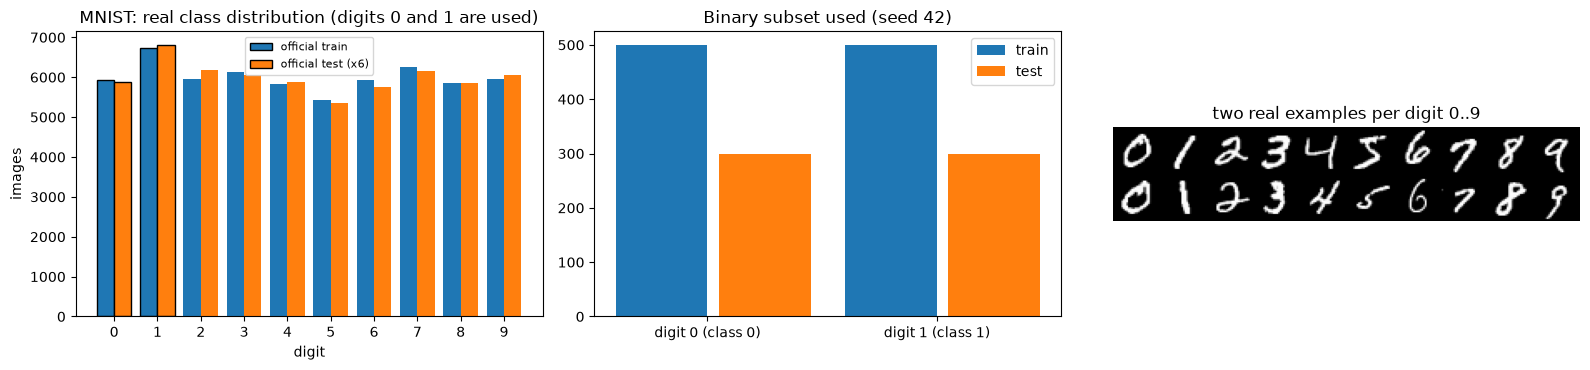

In [6]:
print("== MNIST (Hugging Face mirror ylecun/mnist) ==")
print("  official train images", XTR_ALL.shape, "labels", YTR_ALL.shape, "| official test images", XTE_ALL.shape, "labels", YTE_ALL.shape)
feat = [f"pixel_{i}_{j}" for i in range(28) for j in range(28)]
print("  features: 784 pixel intensities (uint8 0..255, scaled to [0,1]):", feat[:3], "...", feat[-1])
print("  model inputs derived from them: 16 pooled pixels -> PCA components", [f"PC{i+1}" for i in range(N_QUBITS)], "-> angles in [0, pi]")
print("  original label values:", np.unique(YTR_ALL).tolist(), "(digit classes)")
cnt_tr = np.bincount(YTR_ALL, minlength=10); cnt_te = np.bincount(YTE_ALL, minlength=10)
print("  official train class counts:", dict(enumerate(cnt_tr.tolist())))
print("  official test  class counts:", dict(enumerate(cnt_te.tolist())))
D0 = make_split(SEED)
print(f"  seed {SEED} subset used by the models: train {D0['xtr'].shape} (digit 0: {int((D0['ytr']==0).sum())}, digit 1: {int((D0['ytr']==1).sum())}),",
      f"test {D0['xte'].shape} (digit 0: {int((D0['yte']==0).sum())}, digit 1: {int((D0['yte']==1).sum())})")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
ax = axes[0]
ax.bar(np.arange(10) - 0.2, cnt_tr, 0.4, label="official train"); ax.bar(np.arange(10) + 0.2, cnt_te * 6, 0.4, label="official test (x6)")
for d in DIGITS: ax.patches[d].set_edgecolor("k"); ax.patches[d + 10].set_edgecolor("k")
ax.set_xticks(range(10)); ax.set_title("MNIST: real class distribution (digits 0 and 1 are used)"); ax.set_xlabel("digit"); ax.set_ylabel("images"); ax.legend(fontsize=8)
ax = axes[1]
ax.bar([0, 1], [(D0["ytr"] == 0).sum(), (D0["ytr"] == 1).sum()], 0.4, label="train", color="tab:blue")
ax.bar([0.45, 1.45], [(D0["yte"] == 0).sum(), (D0["yte"] == 1).sum()], 0.4, label="test", color="tab:orange")
ax.set_xticks([0.2, 1.2]); ax.set_xticklabels(["digit 0 (class 0)", "digit 1 (class 1)"]); ax.set_title(f"Binary subset used (seed {SEED})"); ax.legend()
ax = axes[2]
ex = np.concatenate([np.concatenate([XTR_ALL[np.where(YTR_ALL == c)[0][k]] for c in range(10)], 1) for k in range(2)], 0)
ax.imshow(ex, cmap="gray"); ax.set_title("two real examples per digit 0..9"); ax.axis("off")
plt.tight_layout(); plt.show()

explained variance ratio of the 4 PCA components (train): [0.493 0.19  0.091 0.067] | sum 0.841


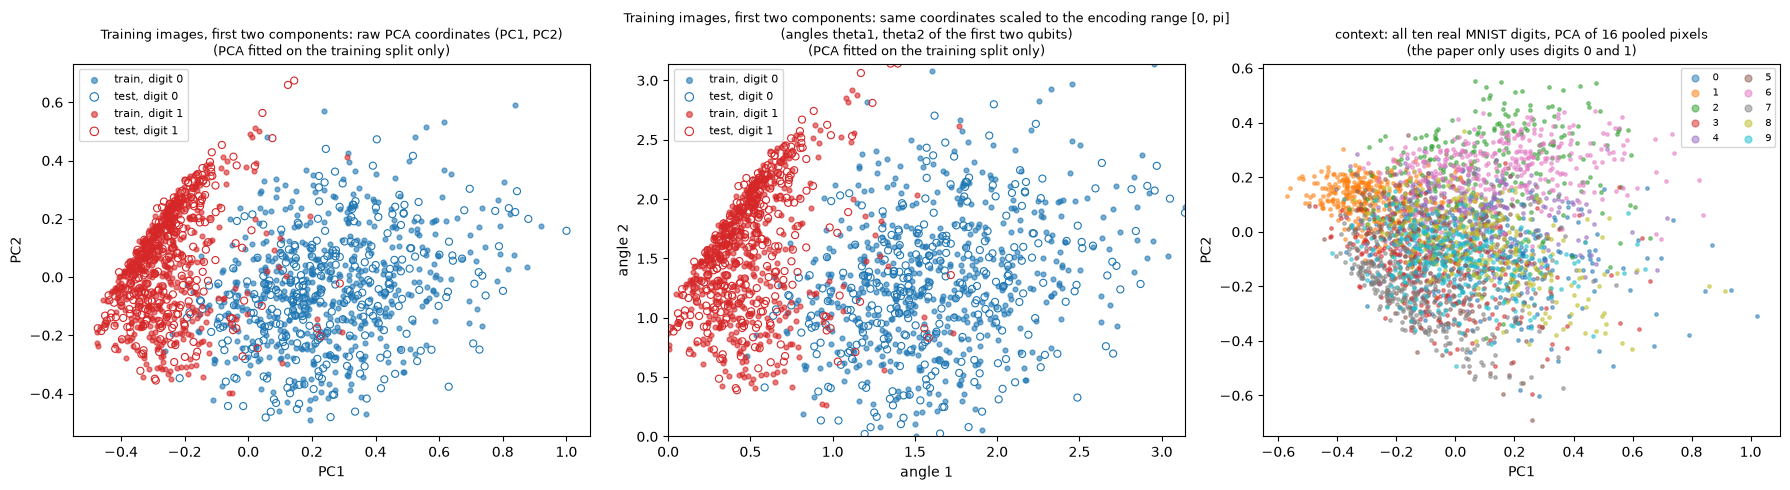

In [7]:
fe0 = FrontEnd().fit(D0["xtr"])
Ztr, Zte = fe0.pca_scores(D0["xtr"]), fe0.pca_scores(D0["xte"])
Atr = fe0.angles_np(D0["xtr"]); Ate = np.clip(fe0.angles_np(D0["xte"]), 0, np.pi)
print("explained variance ratio of the 4 PCA components (train):", np.round(fe0.pca.explained_variance_ratio_, 3), "| sum", round(float(fe0.pca.explained_variance_ratio_.sum()), 3))

# Context: all ten digits with their real labels, PCA of the pooled pixels fitted on a 3000-image training sample
rngc = np.random.default_rng(SEED); ic = rngc.choice(len(XTR_ALL), 3000, replace=False); it = rngc.choice(len(XTE_ALL), 1000, replace=False)
P10 = FrontEnd.pool_np(XTR_ALL[ic].astype(np.float32) / 255.); pca10 = PCA(2, random_state=SEED).fit(P10)
Z10tr = pca10.transform(P10); Z10te = pca10.transform(FrontEnd.pool_np(XTE_ALL[it].astype(np.float32) / 255.))

cmap01 = {0: "tab:blue", 1: "tab:red"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for j, (A, B, ttl, xl) in enumerate([(Ztr[:, :2], Zte[:, :2], "raw PCA coordinates (PC1, PC2)", "PC1"), (Atr[:, :2], Ate[:, :2], "same coordinates scaled to the encoding range [0, pi]\n(angles theta1, theta2 of the first two qubits)", "angle 1")]):
    ax = axes[j]
    for c in (0, 1):
        m = D0["ytr"] == c; ax.scatter(A[m, 0], A[m, 1], s=12, color=cmap01[c], alpha=0.6, label=f"train, digit {c}")
        m = D0["yte"] == c; ax.scatter(B[m, 0], B[m, 1], s=26, facecolors="none", edgecolors=cmap01[c], linewidths=0.8, label=f"test, digit {c}")
    ax.set_title(f"Training images, first two components: {ttl}\n(PCA fitted on the training split only)", fontsize=9); ax.set_xlabel(xl); ax.set_ylabel("PC2" if j == 0 else "angle 2")
    if j == 1: ax.set_xlim(0, np.pi); ax.set_ylim(0, np.pi)
    ax.legend(fontsize=8, markerscale=1.2)
ax = axes[2]; cm10 = plt.get_cmap("tab10")
for c in range(10):
    m = YTR_ALL[ic] == c; ax.scatter(Z10tr[m, 0], Z10tr[m, 1], s=6, color=cm10(c), alpha=0.5, label=str(c))
ax.set_title("context: all ten real MNIST digits, PCA of 16 pooled pixels\n(the paper only uses digits 0 and 1)", fontsize=9); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=7, ncol=2, markerscale=2)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper gives no circuit details, so this section fixes and documents them (all `# CHOICE:`; see the table above).

**Model A: VQC (paper Table 1, Figures 3-4).** Four qubits. Encoding: Qiskit's `zz_feature_map(4, reps=2, entanglement="linear")` (Hadamards, single-qubit phases `P(2 x_i)`, and `CX - P(2 (pi - x_i)(pi - x_j)) - CX` on neighbouring pairs, repeated twice). Trainable part: `real_amplitudes(4, reps=3)` (a layer of `RY(theta)` on every qubit, then three blocks of reverse-linear CNOT entanglement followed by an `RY` layer: **16 trainable angles**). The data angles `x_i` fed to the feature map are `scale * angle_i` where `scale` (0.25, 0.5 or 1) is the encoding bandwidth chosen on a validation split; the drawn circuit shows the symbolic `x[i]`. Read-out: qubit 0 in the Z basis; `P(qubit 0 = 1)` is the probability of class "digit 1" (Qiskit's `VQC` interprets bit strings for two classes as `bitstring mod 2`, which is exactly the value of qubit 0).

**Model B: QSVM (conclusion).** The same ZZFeatureMap defines the fidelity kernel `k(a, b) = |<0| U(b)^dagger U(a) |0>|^2`, evaluated by the *compute-uncompute* circuit `U(a)` followed by `U(b)^dagger` and the probability of the all-zero outcome. There are no trainable circuit angles (the kernel has one classical hyper-parameter, an angle scale chosen on a validation split); the support-vector weights are fitted classically by `SVC(kernel="precomputed")`.

**Exact simulation for attacks.** An attacker needs input gradients. We therefore simulate both circuits exactly in PyTorch (state vector of 4 qubits, 16 complex amplitudes, automatic differentiation). Below, the two circuits are built in Qiskit, drawn, and the PyTorch simulator is asserted equal to Qiskit's `Statevector` on random inputs (probability of class 1 and kernel entries to `1e-10`). The same assertion is repeated for every trained VQC in the main loop.

In [8]:
# ---- exact differentiable state-vector simulator (axis i of the tensor = qubit i) ----------------------
def apply_1q(s, U, q):
    # apply a single-qubit gate U ((2,2) shared, or (B,2,2) per-sample) to qubit q of a batch of states (B,2,2,2,2)
    s = torch.movedim(s, q + 1, -1); B = s.shape[0]; flat = s.reshape(B, -1, 2)
    out = flat @ U.T if U.dim() == 2 else torch.einsum("bna,bca->bnc", flat, U)
    return torch.movedim(out.reshape(s.shape), -1, q + 1)
def cx(s, c, t):
    s0, s1 = s.select(c + 1, 0), s.select(c + 1, 1)
    s1 = torch.flip(s1, dims=[(t if t < c else t - 1) + 1])
    return torch.stack([s0, s1], dim=c + 1)
H_GATE = torch.tensor([[1, 1], [1, -1]], dtype=torch.complex128) / math.sqrt(2)
def phase_gate(theta):                                    # diag(1, e^{i theta}); theta has shape (B,)
    z = torch.zeros_like(theta)
    return torch.stack([torch.stack([torch.ones_like(theta) + 0j, z + 0j], -1), torch.stack([z + 0j, torch.exp(1j * theta)], -1)], -2)
def ry_gate(theta):                                       # theta is a scalar tensor
    c, sn = torch.cos(theta / 2), torch.sin(theta / 2)
    return torch.stack([torch.stack([c, -sn], -1), torch.stack([sn, c], -1)], -2).to(torch.complex128)
def zero_state(B):
    s = torch.zeros((B,) + (2,) * N_QUBITS, dtype=torch.complex128); s[(slice(None),) + (0,) * N_QUBITS] = 1; return s
def zz_state(a, reps=FM_REPS):                            # ZZFeatureMap(linear entanglement) applied to |0...0>; a: (B, N_QUBITS) angles
    s = zero_state(a.shape[0])
    for _ in range(reps):
        for q in range(N_QUBITS): s = apply_1q(s, H_GATE, q)
        for q in range(N_QUBITS): s = apply_1q(s, phase_gate(2 * a[:, q]), q)
        for i in range(N_QUBITS - 1):
            s = cx(s, i, i + 1); s = apply_1q(s, phase_gate(2 * (math.pi - a[:, i]) * (math.pi - a[:, i + 1])), i + 1); s = cx(s, i, i + 1)
    return s
def ansatz_state(s, th, reps=ANSATZ_REPS):                # RealAmplitudes (reverse_linear entanglement)
    k = 0
    for q in range(N_QUBITS): s = apply_1q(s, ry_gate(th[k]), q); k += 1
    for _ in range(reps):
        for i in range(N_QUBITS - 2, -1, -1): s = cx(s, i, i + 1)
        for q in range(N_QUBITS): s = apply_1q(s, ry_gate(th[k]), q); k += 1
    return s
def prob_qubit0_is_1(s): return (s.abs() ** 2).select(1, 1).reshape(s.shape[0], -1).sum(1)
def kernel_matrix(Sa, Sb):                                # |<a|b>|^2 for flattened states (n,16)
    return (Sa.conj() @ Sb.T).abs() ** 2
N_PARAMS = N_QUBITS * (ANSATZ_REPS + 1)

# ---- the Qiskit circuits that are drawn and used as reference ------------------------------------------
fm = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement="linear")
an = real_amplitudes(N_QUBITS, reps=ANSATZ_REPS, entanglement="reverse_linear")
vqc_circ = fm.compose(an)
vqc_meas = vqc_circ.copy(); vqc_meas.measure_all()
ka = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement="linear", parameter_prefix="a")
kb = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement="linear", parameter_prefix="b")
kern_circ = ka.compose(kb.inverse())                      # U(a) then U(b)^dagger
kern_meas = kern_circ.copy(); kern_meas.measure_all()

def qiskit_p1(angles_row, theta):
    pr = dict(zip(fm.parameters, angles_row)); pr.update(dict(zip(an.parameters, theta)))
    return Statevector(vqc_circ.assign_parameters(pr)).probabilities([0])[1]
def qiskit_kernel(a_row, b_row):
    pr = dict(zip(kern_circ.parameters, list(a_row) + list(b_row)))   # parameter order: a[0..3], b[0..3]
    return Statevector(kern_circ.assign_parameters(pr)).probabilities()[0]

rng = np.random.default_rng(SEED)
a_rand = rng.uniform(0, np.pi, (6, N_QUBITS)); b_rand = rng.uniform(0, np.pi, (6, N_QUBITS)); th_rand = rng.uniform(-np.pi, np.pi, N_PARAMS)
mine_p = prob_qubit0_is_1(ansatz_state(zz_state(torch.tensor(a_rand)), torch.tensor(th_rand))).numpy()
ref_p = np.array([qiskit_p1(a_rand[i], th_rand) for i in range(6)])
mine_k = np.array([kernel_matrix(zz_state(torch.tensor(a_rand[i:i+1])).reshape(1, -1), zz_state(torch.tensor(b_rand[i:i+1])).reshape(1, -1))[0, 0].item() for i in range(6)])
ref_k = np.array([qiskit_kernel(a_rand[i], b_rand[i]) for i in range(6)])
assert np.allclose(mine_p, ref_p, atol=1e-10), (mine_p, ref_p)
assert np.allclose(mine_k, ref_k, atol=1e-10), (mine_k, ref_k)
print("PyTorch simulator == Qiskit Statevector:  max |dP(class 1)| =", float(np.abs(mine_p - ref_p).max()), "| max |dK| =", float(np.abs(mine_k - ref_k).max()))

PyTorch simulator == Qiskit Statevector:  max |dP(class 1)| = 1.6653345369377348e-16 | max |dK| = 5.551115123125783e-17


Model A (VQC):   qubits = 4 | depth (decomposed, without measurement) = 30 | trainable parameters = 16 | data (input) parameters = 4 | gate counts = {'u': 38, 'cx': 21}


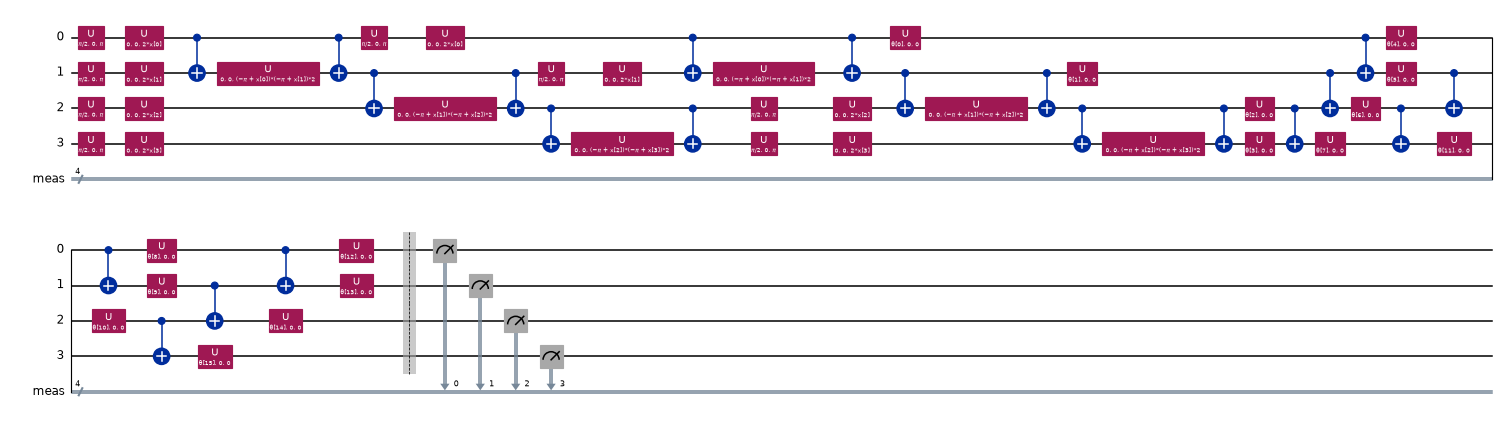

In [9]:
# Model A: the circuit that the VQC executes (measurement of qubit 0 is the class read-out)
vqc_show = vqc_circ.copy(); vqc_show.measure_all()
vqc_dec = vqc_show.decompose(reps=2)
print("Model A (VQC):   qubits =", vqc_circ.num_qubits, "| depth (decomposed, without measurement) =", vqc_circ.decompose(reps=2).depth(),
      "| trainable parameters =", an.num_parameters, "| data (input) parameters =", fm.num_parameters,
      "| gate counts =", dict(vqc_circ.decompose(reps=2).count_ops()))
fig = vqc_dec.draw("mpl", fold=40, scale=0.55)
display(fig); plt.close("all")

Model B (QSVM kernel circuit): qubits = 4 | depth (decomposed) = 38 | trainable circuit parameters = 0 (kernel); data parameters = 8 | gate counts = {'u': 44, 'cx': 24}


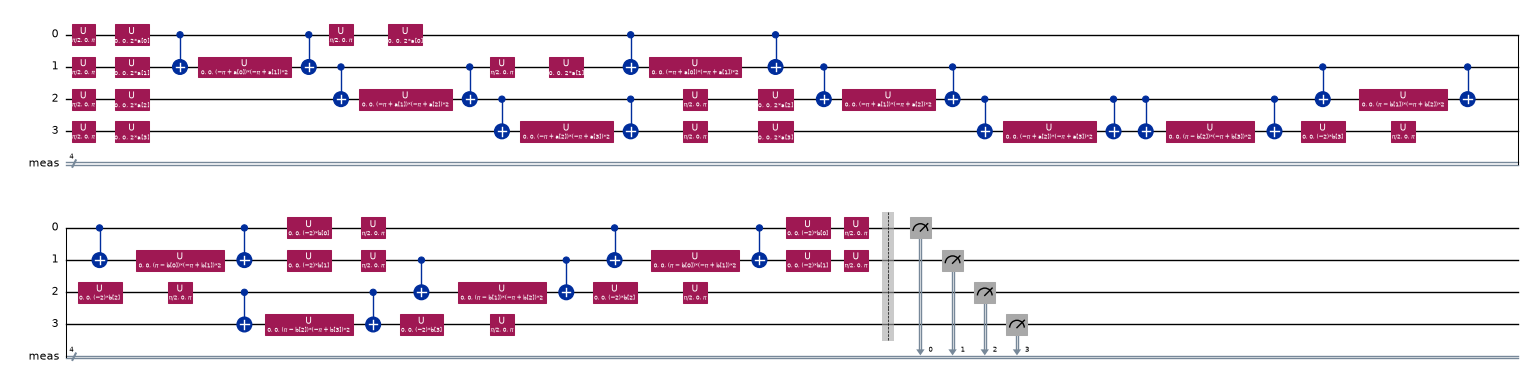

Assumptions where the paper is silent: 4 qubits; ZZFeatureMap reps=2 with linear entanglement; RealAmplitudes reps=3 with reverse-linear CNOTs; qubit-0 read-out; no noise (statevector).


In [10]:
# Model B: the compute-uncompute kernel circuit U(a) then U(b)^dagger; k(a, b) = P(all-zero outcome)
kern_dec = kern_meas.decompose(reps=2)
print("Model B (QSVM kernel circuit): qubits =", kern_circ.num_qubits, "| depth (decomposed) =", kern_circ.decompose(reps=2).depth(),
      "| trainable circuit parameters = 0 (kernel); data parameters =", kern_circ.num_parameters,
      "| gate counts =", dict(kern_circ.decompose(reps=2).count_ops()))
fig = kern_dec.draw("mpl", fold=45, scale=0.5)
display(fig); plt.close("all")
print("Assumptions where the paper is silent: 4 qubits; ZZFeatureMap reps=2 with linear entanglement; RealAmplitudes reps=3 with reverse-linear CNOTs; qubit-0 read-out; no noise (statevector).")

## 3. The models

All models expose the same two functions, so the attacks below treat them identically:

* `score(x)`: a differentiable real number per image whose sign decides the class (positive = digit 1). For the VQC it is `P(class 1) - 1/2`, for the QSVM and the RBF-SVM the SVM decision function, for the neural networks the logit.
* `predict(x)`: the class labels.

| Model | Input | Trained by |
|---|---|---|
| **VQC** (paper's Table 1 model) | 4 angles | Adam on cross-entropy, exact simulator gradients, `VQC_STEPS` steps; angle scale chosen on a validation split |
| **QSVM** (paper's conclusion) | 4 angles | `SVC(C=1)` on the ZZ fidelity kernel; kernel angle scale chosen on a validation split of the training data |
| **MLP** (same 4 angles) | 4 angles | Adam, cross-entropy |
| **SVC-RBF** (same 4 angles) | 4 angles | scikit-learn `SVC(kernel="rbf", C=1, gamma="scale")`, its decision function re-implemented in PyTorch (asserted equal) |
| **Random forest** (same 4 angles) | 4 angles | 100 trees; not differentiable, attacked by transfer from the MLP |
| **CNN** (paper baseline) | 28x28 pixels | 2 conv layers + 2 dense layers, Adam |
| **ViT-tiny** (paper's "transformer") | 28x28 pixels | 16 patches of 7x7, 2 encoder layers, 32 dims, Adam |

In [11]:
class VQCModel:
    name = "VQC (ZZ + RealAmplitudes)"
    def __init__(self, fe, seed):
        self.fe = fe; self.seed = seed; self.scale = 1.0
        self.theta = torch.tensor(np.random.default_rng(seed).uniform(-np.pi, np.pi, N_PARAMS), requires_grad=True)
    def p1_theta(self, ang, theta, scale): return prob_qubit0_is_1(ansatz_state(zz_state(ang * scale), theta))
    def p1(self, ang): return self.p1_theta(ang, self.theta, self.scale)
    def score(self, x): return self.p1(self.fe.angles_t(x)) - 0.5
    def _train(self, ang, ytr, steps, scale):
        theta = torch.tensor(np.random.default_rng(self.seed).uniform(-np.pi, np.pi, N_PARAMS), requires_grad=True)
        y = torch.tensor(ytr, dtype=torch.float64); rng = np.random.default_rng(self.seed); opt = torch.optim.Adam([theta], lr=VQC_LR); hist = []
        for st in range(steps):
            idx = rng.choice(len(ang), min(VQC_BATCH, len(ang)), replace=False)
            p = self.p1_theta(ang[idx], theta, scale).clamp(1e-9, 1 - 1e-9)
            loss = -(y[idx] * torch.log(p) + (1 - y[idx]) * torch.log(1 - p)).mean()
            opt.zero_grad(); loss.backward(); opt.step(); hist.append(float(loss.detach()))
        return theta, hist
    def fit(self, xtr, ytr):
        ang = self.fe.angles_t(xtr).detach(); n = len(ang)
        perm = np.random.default_rng(self.seed).permutation(n); nv = n // 5; va, tr = perm[:nv], perm[nv:]
        best = (-1, None)
        for sc in VQC_SCALES:                         # angle scale (bandwidth) chosen on a validation split of the training data only
            th, _ = self._train(ang[tr], ytr[tr], max(VQC_STEPS // 2, 20), sc)
            with torch.no_grad(): acc = ((self.p1_theta(ang[va], th, sc) > 0.5).numpy().astype(int) == ytr[va]).mean()
            if acc > best[0] + 1e-12: best = (acc, sc)
        self.scale, self.val_acc = best[1], best[0]
        th, self.hist = self._train(ang, ytr, VQC_STEPS, self.scale)
        self.theta = th
        return self
    def predict(self, x):
        with torch.no_grad(): return (self.score(x) > 0).numpy().astype(int)
class QSVMModel:
    name = "QSVM (ZZ fidelity kernel)"
    def __init__(self, fe, seed): self.fe = fe; self.seed = seed
    def states(self, ang, scale): return zz_state(ang * scale).reshape(len(ang), -1)
    def fit(self, xtr, ytr):
        ang = self.fe.angles_t(xtr).detach(); n = len(ang)
        perm = np.random.default_rng(self.seed).permutation(n); nv = n // 5; va, tr = perm[:nv], perm[nv:]
        best = (-1, None)
        for sc in QSVM_SCALES:                                   # bandwidth chosen on a validation split of the training data only
            S = self.states(ang, sc)
            clf = SVC(kernel="precomputed", C=SVM_C).fit(kernel_matrix(S[tr], S[tr]).numpy(), ytr[tr])
            acc = (clf.predict(kernel_matrix(S[va], S[tr]).numpy()) == ytr[va]).mean()
            if acc > best[0] + 1e-12: best = (acc, sc)
        self.scale, self.val_acc = best[1], best[0]
        S = self.states(ang, self.scale)
        self.clf = SVC(kernel="precomputed", C=SVM_C).fit(kernel_matrix(S, S).numpy(), ytr)
        sv = self.clf.support_
        self.S_sv = S[sv].detach(); self.dual = torch.tensor(self.clf.dual_coef_[0]); self.b = float(self.clf.intercept_[0])
        return self
    def score(self, x):
        S = self.states(self.fe.angles_t(x), self.scale)
        return self.dual @ kernel_matrix(self.S_sv, S) + self.b
    def predict(self, x):
        with torch.no_grad(): return (self.score(x) > 0).numpy().astype(int)

class SVCRBFModel:
    name = "SVC-RBF (same 4 angles)"
    def __init__(self, fe, seed): self.fe = fe; self.seed = seed
    def fit(self, xtr, ytr):
        ang = self.fe.angles_t(xtr).detach().numpy()
        self.clf = SVC(kernel="rbf", C=SVM_C, gamma="scale").fit(ang, ytr)
        self.gamma = float(self.clf._gamma); self.sv = torch.tensor(self.clf.support_vectors_)
        self.dual = torch.tensor(self.clf.dual_coef_[0]); self.b = float(self.clf.intercept_[0]); return self
    def score(self, x):
        a = self.fe.angles_t(x); d2 = ((a[:, None, :] - self.sv[None]) ** 2).sum(-1)
        return torch.exp(-self.gamma * d2) @ self.dual + self.b
    def predict(self, x):
        with torch.no_grad(): return (self.score(x) > 0).numpy().astype(int)

class TorchNNModel:
    # generic wrapper for MLP / CNN / ViT: net maps pre(x) to one logit
    def __init__(self, name, net, pre, dtype, seed, lr=2e-3, batch=32):
        self.name, self.net, self.pre, self.dtype, self.seed, self.lr, self.batch = name, net, pre, dtype, seed, lr, batch
    def score(self, x): return self.net(self.pre(x).to(self.dtype)).reshape(-1).to(torch.float64)
    def fit(self, xtr, ytr):
        y = torch.tensor(ytr, dtype=torch.float64); g = torch.Generator().manual_seed(self.seed)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr); n = len(xtr); self.hist = []
        for ep in range(NN_EPOCHS):
            perm = torch.randperm(n, generator=g)
            for i in range(0, n, self.batch):
                idx = perm[i:i + self.batch]
                loss = F.binary_cross_entropy_with_logits(self.score(xtr[idx]), y[idx])
                opt.zero_grad(); loss.backward(); opt.step(); self.hist.append(float(loss.detach()))
        self.net.eval(); return self
    def predict(self, x):
        with torch.no_grad(): return np.concatenate([(self.score(x[i:i + 500]) > 0).numpy().astype(int) for i in range(0, len(x), 500)])

class ViTNet(nn.Module):
    def __init__(self, d=32, heads=2, layers=2, patch=7):
        super().__init__()
        self.n = 28 // patch; self.patch = patch
        self.proj = nn.Linear(patch * patch, d); self.cls = nn.Parameter(torch.zeros(1, 1, d)); self.pos = nn.Parameter(torch.randn(1, self.n ** 2 + 1, d) * 0.02)
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, 64, dropout=0.0, batch_first=True), layers, enable_nested_tensor=False)
        self.head = nn.Linear(d, 1)
    def forward(self, x):                                      # x: (B, 784)
        B = x.shape[0]; p = x.reshape(B, self.n, self.patch, self.n, self.patch).permute(0, 1, 3, 2, 4).reshape(B, self.n ** 2, -1)
        t = torch.cat([self.cls.expand(B, -1, -1), self.proj(p - 0.5)], 1) + self.pos
        return self.head(self.enc(t)[:, 0])

def make_cnn():
    return nn.Sequential(nn.Unflatten(1, (1, 28, 28)), nn.Conv2d(1, 8, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(8, 16, 3), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(16 * 5 * 5, 32), nn.ReLU(), nn.Linear(32, 1))

def build_models(fe, seed):
    torch.manual_seed(seed)
    mlp = nn.Sequential(nn.Linear(N_QUBITS, 16), nn.Tanh(), nn.Linear(16, 16), nn.Tanh(), nn.Linear(16, 1)).double()
    return [VQCModel(fe, seed), QSVMModel(fe, seed), SVCRBFModel(fe, seed),
            TorchNNModel("MLP (same 4 angles)", mlp, fe.angles_t, torch.float64, seed, lr=1e-2),
            TorchNNModel("CNN (28x28)", make_cnn().float(), lambda x: x, torch.float32, seed),
            TorchNNModel("ViT-tiny (28x28)", ViTNet().float(), lambda x: x, torch.float32, seed)]

## 4. The attacks: FGSM and PGD

Both attacks work on the 28x28 pixels (flattened to 784 numbers in `[0, 1]`) and stay in the L-infinity ball of radius `epsilon` around the clean image.

* **FGSM** (Goodfellow et al.): `x_adv = clip(x + epsilon * sign(grad_x L))`, one step.
* **PGD** (Madry et al.): repeat `x <- clip(x + alpha * sign(grad_x L))`, project back onto the `epsilon` ball and `[0, 1]` after every step. We use 10 steps and no random start (deterministic). *PGD-eps* sets `alpha = 2.5 * epsilon / 10`; *PGD-fixed* sets `alpha = 0.01` for every `epsilon`.

`L` is the loss of the true class. For a binary problem the sign of the cross-entropy gradient equals the sign of the gradient of `-s * score(x)` with `s = +1` for digit 1 and `-1` for digit 0, so we use that (it is the same direction and it does not saturate for very confident models).

In [12]:
def sgn(y): return torch.tensor(2.0 * np.asarray(y) - 1.0, dtype=torch.float64)

def grad_sign(model, x, y):
    x = x.clone().requires_grad_(True)
    loss = (-sgn(y) * model.score(x)).sum()
    g, = torch.autograd.grad(loss, x)
    return g.sign()

def fgsm(model, x, y, eps):
    return (x + eps * grad_sign(model, x, y)).clamp(0, 1).detach()

def pgd(model, x, y, eps, alpha, steps=PGD_STEPS):
    xa = x.clone()
    for _ in range(steps):
        xa = xa + alpha * grad_sign(model, xa, y)
        xa = (x + (xa - x).clamp(-eps, eps)).clamp(0, 1).detach()
    return xa

def attack(kind, model, x, y, eps):
    if kind == "FGSM": return fgsm(model, x, y, eps)
    if kind == "PGD-eps": return pgd(model, x, y, eps, PGD_ALPHA_FACTOR * eps / PGD_STEPS)
    if kind == "PGD-fixed": return pgd(model, x, y, eps, PGD_ALPHA_FIXED)
    raise ValueError(kind)
ATTACKS = ["FGSM", "PGD-eps", "PGD-fixed"]

## 5. Running the experiment

For every seed we draw a new balanced train/test subset, fit the front end on the training split, train all models, and attack the **whole test subset** with every attack and every `epsilon` (accuracy under attack counts every test image, including those that were already misclassified, as in the paper's "accuracy on perturbed data"). The random forest is attacked with the adversarial images crafted against the MLP (transfer). For the first seed we also check, for the trained VQC, that the PyTorch simulator still equals the Qiskit circuit, and that the PyTorch re-implementations of the SVMs equal their scikit-learn originals.

In [13]:
rows, clean_rows, KEEP = [], [], {}
t_run = time.time()
for si in range(N_SEEDS):
    seed = SEED + si
    D = make_split(seed); fe = FrontEnd().fit(D["xtr"])
    xtr = torch.tensor(D["xtr"].reshape(len(D["xtr"]), -1).astype(np.float64)); xte = torch.tensor(D["xte"].reshape(len(D["xte"]), -1).astype(np.float64))
    ytr, yte = D["ytr"], D["yte"]
    models, t_train = build_models(fe, seed), {}
    for m in models:
        t0 = time.time(); m.fit(xtr, ytr); t_train[m.name] = time.time() - t0
    ang_tr = fe.angles_t(xtr).detach().numpy()
    rf = RandomForestClassifier(n_estimators=100, random_state=seed).fit(ang_tr, ytr)
    RF_NAME = "Random forest (same 4 angles, transfer from MLP)"
    mlp = [m for m in models if m.name.startswith("MLP")][0]
    def rf_pred(x): return rf.predict(fe.angles_t(x).detach().numpy())

    # --- equivalence checks (first seed): trained VQC == Qiskit circuit, SVM re-implementations == scikit-learn
    if si == 0:
        vq = models[0]; th = vq.theta.detach().numpy(); a5 = fe.angles_np(D["xte"][:5])
        ref = np.array([qiskit_p1(a5[i] * vq.scale, th) for i in range(5)])   # Qiskit circuit evaluated at the scaled angles
        mine = vq.p1(torch.tensor(a5)).detach().numpy()
        assert np.allclose(ref, mine, atol=1e-9), (ref, mine)
        qs = models[1]; a20 = fe.angles_t(xte[:20]).detach()
        assert np.allclose(qs.score(xte[:20]).detach().numpy(), qs.clf.decision_function(kernel_matrix(qs.states(a20, qs.scale), qs.states(fe.angles_t(xtr).detach(), qs.scale)).numpy()), atol=1e-8)
        sv = models[2]
        assert np.allclose(sv.score(xte[:20]).detach().numpy(), sv.clf.decision_function(fe.angles_t(xte[:20]).detach().numpy()), atol=1e-8)
        print("seed", seed, ": trained VQC == Qiskit circuit (max |dP| =", float(np.abs(ref - mine).max()), "); QSVM and SVC-RBF torch scores == scikit-learn decision_function")
        KEEP.update(D=D, fe=fe, models=models, xte=xte, yte=yte, rf=rf, adv={})

    # --- clean accuracies
    for m in models: clean_rows.append(dict(seed=seed, model=m.name, acc=float((m.predict(xte) == yte).mean()), train_s=t_train[m.name]))
    clean_rows.append(dict(seed=seed, model=RF_NAME, acc=float((rf_pred(xte) == yte).mean()), train_s=np.nan))
    for m in models + [None]:
        nm = RF_NAME if m is None else m.name
        rows.append(dict(seed=seed, attack="clean", eps=0.0, model=nm, acc=[r for r in clean_rows if r["seed"] == seed and r["model"] == nm][0]["acc"]))
    # --- attacks
    t_att = time.time()
    for kind in ATTACKS:
        for eps in EPS_LIST:
            for m in models:
                xa = attack(kind, m, xte, yte, eps)
                rows.append(dict(seed=seed, attack=kind, eps=eps, model=m.name, acc=float((m.predict(xa) == yte).mean())))
                if m is mlp:
                    rows.append(dict(seed=seed, attack=kind, eps=eps, model=RF_NAME, acc=float((rf_pred(xa) == yte).mean())))
                if si == 0: KEEP["adv"][(kind, eps, m.name)] = xa[:8].clone()
    print(f"seed {seed}: trained in {sum(t_train.values()):.0f}s, attacked in {time.time() - t_att:.0f}s | clean acc:",
          {r['model'].split(' ')[0]: round(r['acc'], 3) for r in clean_rows if r['seed'] == seed})
RES = pd.DataFrame(rows); CLEAN = pd.DataFrame(clean_rows)
print(f"total experiment time {time.time() - t_run:.0f}s")

seed 42 : trained VQC == Qiskit circuit (max |dP| = 6.661338147750939e-16 ); QSVM and SVC-RBF torch scores == scikit-learn decision_function


seed 42: trained in 260s, attacked in 272s | clean acc: {'VQC': 0.827, 'QSVM': 0.978, 'SVC-RBF': 0.988, 'MLP': 0.985, 'CNN': 0.998, 'ViT-tiny': 0.993, 'Random': 0.978}


seed 43: trained in 246s, attacked in 271s | clean acc: {'VQC': 0.763, 'QSVM': 0.965, 'SVC-RBF': 0.985, 'MLP': 0.982, 'CNN': 1.0, 'ViT-tiny': 1.0, 'Random': 0.973}


seed 44: trained in 100s, attacked in 95s | clean acc: {'VQC': 0.882, 'QSVM': 0.978, 'SVC-RBF': 0.99, 'MLP': 0.98, 'CNN': 0.993, 'ViT-tiny': 0.99, 'Random': 0.977}


seed 45: trained in 252s, attacked in 332s | clean acc: {'VQC': 0.857, 'QSVM': 0.948, 'SVC-RBF': 0.985, 'MLP': 0.987, 'CNN': 0.997, 'ViT-tiny': 0.997, 'Random': 0.98}


seed 46: trained in 288s, attacked in 175s | clean acc: {'VQC': 0.86, 'QSVM': 0.978, 'SVC-RBF': 0.99, 'MLP': 0.96, 'CNN': 0.998, 'ViT-tiny': 1.0, 'Random': 0.983}


total experiment time 2304s


In [14]:
# Clean accuracy and training time (mean +- std over seeds), plus classical references on ALL 784 pixels
ref_rows = []
for si in range(N_SEEDS):
    D = make_split(SEED + si); Xa, Xb = D["xtr"].reshape(len(D["xtr"]), -1), D["xte"].reshape(len(D["xte"]), -1)
    ref_rows.append(dict(model="Random forest (all 784 pixels)", acc=RandomForestClassifier(100, random_state=SEED + si).fit(Xa, D["ytr"]).score(Xb, D["yte"])))
    ref_rows.append(dict(model="SVC-RBF (all 784 pixels)", acc=SVC(C=SVM_C, gamma="scale").fit(Xa, D["ytr"]).score(Xb, D["yte"])))
tab = pd.concat([CLEAN[["model", "acc", "train_s"]], pd.DataFrame(ref_rows)]).groupby("model", sort=False).agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"), train_s=("train_s", "mean")).round(4)
display(tab)
print(f"paper's clean VQC accuracy (text of Section 5.1, PGD experiment): {PAPER_CLEAN_PGD}")

,acc_mean,acc_std,train_s
model,,,
VQC (ZZ + RealAmplitudes),0.8377,0.0459,70.9978
QSVM (ZZ fidelity kernel),0.9697,0.0132,1.5196
SVC-RBF (same 4 angles),0.9877,0.0025,0.0469
MLP (same 4 angles),0.9787,0.0108,8.6059
CNN (28x28),0.9973,0.0025,47.9819
ViT-tiny (28x28),0.9960,0.0043,99.9838
"Random forest (same 4 angles, transfer from MLP)",0.9783,0.0037,NaN
Random forest (all 784 pixels),0.9990,0.0009,NaN
SVC-RBF (all 784 pixels),0.9983,0.0012,NaN


paper's clean VQC accuracy (text of Section 5.1, PGD experiment): 0.8686


## 6. Results: accuracy under attack (the paper's Table 1 and Figures 3-4, for every model)

The tables give the mean accuracy over seeds (and the standard deviation across seeds). The figure redraws the paper's accuracy-versus-epsilon plots: left FGSM, middle PGD-eps, right PGD-fixed; the paper's VQC values (Table 1) are overlaid as a dashed black line.

In [15]:
AGG = RES.groupby(["attack", "eps", "model"], sort=False).acc.agg(["mean", "std"]).reset_index()
def table(kind):
    t = AGG[AGG.attack.isin(["clean", kind])].copy()
    t["cell"] = t.apply(lambda r: f"{r['mean']:.3f} +- {0 if pd.isna(r['std']) else r['std']:.3f}", axis=1)
    return t.pivot(index="model", columns="eps", values="cell").reindex([m for m in AGG.model.unique()])
for kind in ATTACKS:
    print(f"=== accuracy under {kind} (mean +- std over {N_SEEDS} seeds, {N_TEST} test images per seed); column 0.0 = clean ===")
    display(table(kind))

=== accuracy under FGSM (mean +- std over 5 seeds, 600 test images per seed); column 0.0 = clean ===


eps,0.00,0.01,0.05,0.10,0.20,0.30,0.40
model,,,,,,,
VQC (ZZ + RealAmplitudes),0.838 +- 0.046,0.771 +- 0.073,0.520 +- 0.098,0.430 +- 0.040,0.458 +- 0.043,0.524 +- 0.025,0.465 +- 0.059
QSVM (ZZ fidelity kernel),0.970 +- 0.013,0.953 +- 0.014,0.805 +- 0.056,0.542 +- 0.066,0.467 +- 0.052,0.435 +- 0.046,0.436 +- 0.028
SVC-RBF (same 4 angles),0.988 +- 0.003,0.981 +- 0.003,0.829 +- 0.041,0.492 +- 0.021,0.395 +- 0.017,0.363 +- 0.024,0.358 +- 0.025
MLP (same 4 angles),0.979 +- 0.011,0.968 +- 0.011,0.755 +- 0.134,0.458 +- 0.031,0.400 +- 0.049,0.305 +- 0.076,0.197 +- 0.083
CNN (28x28),0.997 +- 0.003,0.997 +- 0.003,0.994 +- 0.004,0.989 +- 0.007,0.940 +- 0.038,0.677 +- 0.150,0.374 +- 0.101
ViT-tiny (28x28),0.996 +- 0.004,0.993 +- 0.006,0.968 +- 0.029,0.883 +- 0.054,0.713 +- 0.102,0.663 +- 0.122,0.626 +- 0.112
"Random forest (same 4 angles, transfer from MLP)",0.978 +- 0.004,0.966 +- 0.008,0.872 +- 0.034,0.497 +- 0.013,0.423 +- 0.029,0.355 +- 0.059,0.281 +- 0.070


=== accuracy under PGD-eps (mean +- std over 5 seeds, 600 test images per seed); column 0.0 = clean ===


eps,0.00,0.01,0.05,0.10,0.20,0.30,0.40
model,,,,,,,
VQC (ZZ + RealAmplitudes),0.838 +- 0.046,0.769 +- 0.077,0.402 +- 0.167,0.186 +- 0.060,0.182 +- 0.106,0.212 +- 0.099,0.301 +- 0.116
QSVM (ZZ fidelity kernel),0.970 +- 0.013,0.953 +- 0.014,0.740 +- 0.091,0.430 +- 0.031,0.358 +- 0.031,0.363 +- 0.044,0.400 +- 0.044
SVC-RBF (same 4 angles),0.988 +- 0.003,0.981 +- 0.003,0.814 +- 0.048,0.459 +- 0.013,0.351 +- 0.026,0.284 +- 0.031,0.281 +- 0.031
MLP (same 4 angles),0.979 +- 0.011,0.968 +- 0.011,0.753 +- 0.135,0.455 +- 0.034,0.399 +- 0.049,0.299 +- 0.074,0.183 +- 0.084
CNN (28x28),0.997 +- 0.003,0.997 +- 0.003,0.993 +- 0.005,0.986 +- 0.005,0.894 +- 0.058,0.414 +- 0.077,0.160 +- 0.154
ViT-tiny (28x28),0.996 +- 0.004,0.993 +- 0.006,0.956 +- 0.048,0.743 +- 0.158,0.366 +- 0.114,0.146 +- 0.100,0.052 +- 0.049
"Random forest (same 4 angles, transfer from MLP)",0.978 +- 0.004,0.966 +- 0.008,0.874 +- 0.033,0.503 +- 0.015,0.411 +- 0.033,0.306 +- 0.071,0.177 +- 0.082


=== accuracy under PGD-fixed (mean +- std over 5 seeds, 600 test images per seed); column 0.0 = clean ===


eps,0.00,0.01,0.05,0.10,0.20,0.30,0.40
model,,,,,,,
VQC (ZZ + RealAmplitudes),0.838 +- 0.046,0.770 +- 0.074,0.393 +- 0.175,0.140 +- 0.104,0.140 +- 0.104,0.140 +- 0.104,0.140 +- 0.104
QSVM (ZZ fidelity kernel),0.970 +- 0.013,0.953 +- 0.014,0.740 +- 0.091,0.430 +- 0.047,0.430 +- 0.047,0.430 +- 0.047,0.430 +- 0.047
SVC-RBF (same 4 angles),0.988 +- 0.003,0.981 +- 0.003,0.815 +- 0.048,0.469 +- 0.016,0.469 +- 0.016,0.469 +- 0.016,0.469 +- 0.016
MLP (same 4 angles),0.979 +- 0.011,0.968 +- 0.011,0.753 +- 0.135,0.455 +- 0.034,0.455 +- 0.034,0.455 +- 0.034,0.455 +- 0.034
CNN (28x28),0.997 +- 0.003,0.997 +- 0.003,0.993 +- 0.005,0.987 +- 0.005,0.987 +- 0.005,0.987 +- 0.005,0.987 +- 0.005
ViT-tiny (28x28),0.996 +- 0.004,0.993 +- 0.006,0.956 +- 0.048,0.788 +- 0.156,0.788 +- 0.156,0.788 +- 0.156,0.788 +- 0.156
"Random forest (same 4 angles, transfer from MLP)",0.978 +- 0.004,0.966 +- 0.008,0.874 +- 0.033,0.502 +- 0.011,0.502 +- 0.011,0.502 +- 0.011,0.502 +- 0.011


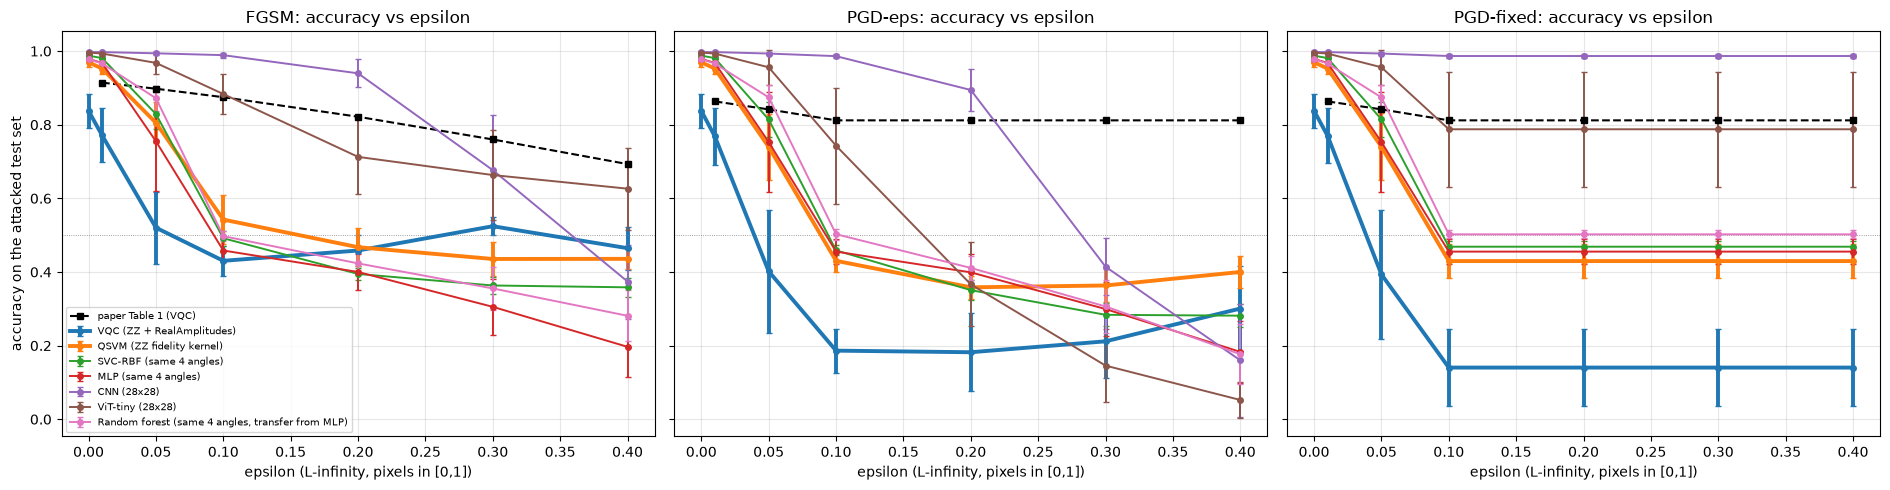

In [16]:
colors = {nm: c for nm, c in zip(AGG.model.unique(), plt.get_cmap("tab10").colors)}
fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharey=True)
for ax, kind in zip(axes, ATTACKS):
    for nm in AGG.model.unique():
        t = AGG[(AGG.model == nm) & (AGG.attack.isin(["clean", kind]))].sort_values("eps")
        lw = 2.8 if nm.startswith(("VQC", "QSVM")) else 1.4
        ax.errorbar(t.eps, t["mean"], yerr=t["std"].fillna(0), marker="o", ms=4, lw=lw, color=colors[nm], capsize=2, label=nm)
    pp = PAPER_FGSM if kind == "FGSM" else PAPER_PGD
    ax.plot(list(pp), list(pp.values()), "k--", marker="s", ms=5, label="paper Table 1 (VQC)")
    ax.set_title(f"{kind}: accuracy vs epsilon"); ax.set_xlabel("epsilon (L-infinity, pixels in [0,1])"); ax.axhline(0.5, color="grey", lw=0.6, ls=":"); ax.grid(alpha=0.3)
axes[0].set_ylabel("accuracy on the attacked test set"); axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

In [17]:
# Robustness score of the paper (Section 3.2): percentage drop in accuracy from clean to adversarial data
clean = AGG[AGG.attack == "clean"].set_index("model")["mean"]
rs = AGG[AGG.attack != "clean"].copy(); rs["drop_pct"] = rs.apply(lambda r: 100 * (clean[r["model"]] - r["mean"]), axis=1)
for kind in ATTACKS:
    print(f"=== robustness score = accuracy drop in percentage points, {kind} (lower = more robust) ===")
    display(rs[rs.attack == kind].pivot(index="model", columns="eps", values="drop_pct").reindex(list(AGG.model.unique())).round(1))

=== robustness score = accuracy drop in percentage points, FGSM (lower = more robust) ===


eps,0.01,0.05,0.10,0.20,0.30,0.40
model,,,,,,
VQC (ZZ + RealAmplitudes),6.6,31.7,40.7,37.9,31.3,37.3
QSVM (ZZ fidelity kernel),1.7,16.4,42.7,50.2,53.4,53.4
SVC-RBF (same 4 angles),0.7,15.9,49.6,59.3,62.4,62.9
MLP (same 4 angles),1.1,22.4,52.0,57.9,67.3,78.2
CNN (28x28),0.0,0.3,0.8,5.8,32.1,62.3
ViT-tiny (28x28),0.3,2.8,11.3,28.3,33.3,37.0
"Random forest (same 4 angles, transfer from MLP)",1.2,10.6,48.1,55.5,62.3,69.7


=== robustness score = accuracy drop in percentage points, PGD-eps (lower = more robust) ===


eps,0.01,0.05,0.10,0.20,0.30,0.40
model,,,,,,
VQC (ZZ + RealAmplitudes),6.9,43.6,65.1,65.6,62.6,53.7
QSVM (ZZ fidelity kernel),1.7,23.0,53.9,61.1,60.6,57.0
SVC-RBF (same 4 angles),0.7,17.3,52.9,63.7,70.4,70.6
MLP (same 4 angles),1.1,22.6,52.3,58.0,67.9,79.6
CNN (28x28),0.0,0.4,1.1,10.3,58.3,83.7
ViT-tiny (28x28),0.3,4.0,25.3,63.0,85.0,94.4
"Random forest (same 4 angles, transfer from MLP)",1.2,10.4,47.6,56.7,67.2,80.2


=== robustness score = accuracy drop in percentage points, PGD-fixed (lower = more robust) ===


eps,0.01,0.05,0.10,0.20,0.30,0.40
model,,,,,,
VQC (ZZ + RealAmplitudes),6.7,44.4,69.7,69.7,69.7,69.7
QSVM (ZZ fidelity kernel),1.7,23.0,54.0,54.0,54.0,54.0
SVC-RBF (same 4 angles),0.7,17.3,51.9,51.9,51.9,51.9
MLP (same 4 angles),1.1,22.6,52.3,52.3,52.3,52.3
CNN (28x28),0.0,0.4,1.1,1.1,1.1,1.1
ViT-tiny (28x28),0.3,4.0,20.8,20.8,20.8,20.8
"Random forest (same 4 angles, transfer from MLP)",1.2,10.4,47.6,47.6,47.6,47.6


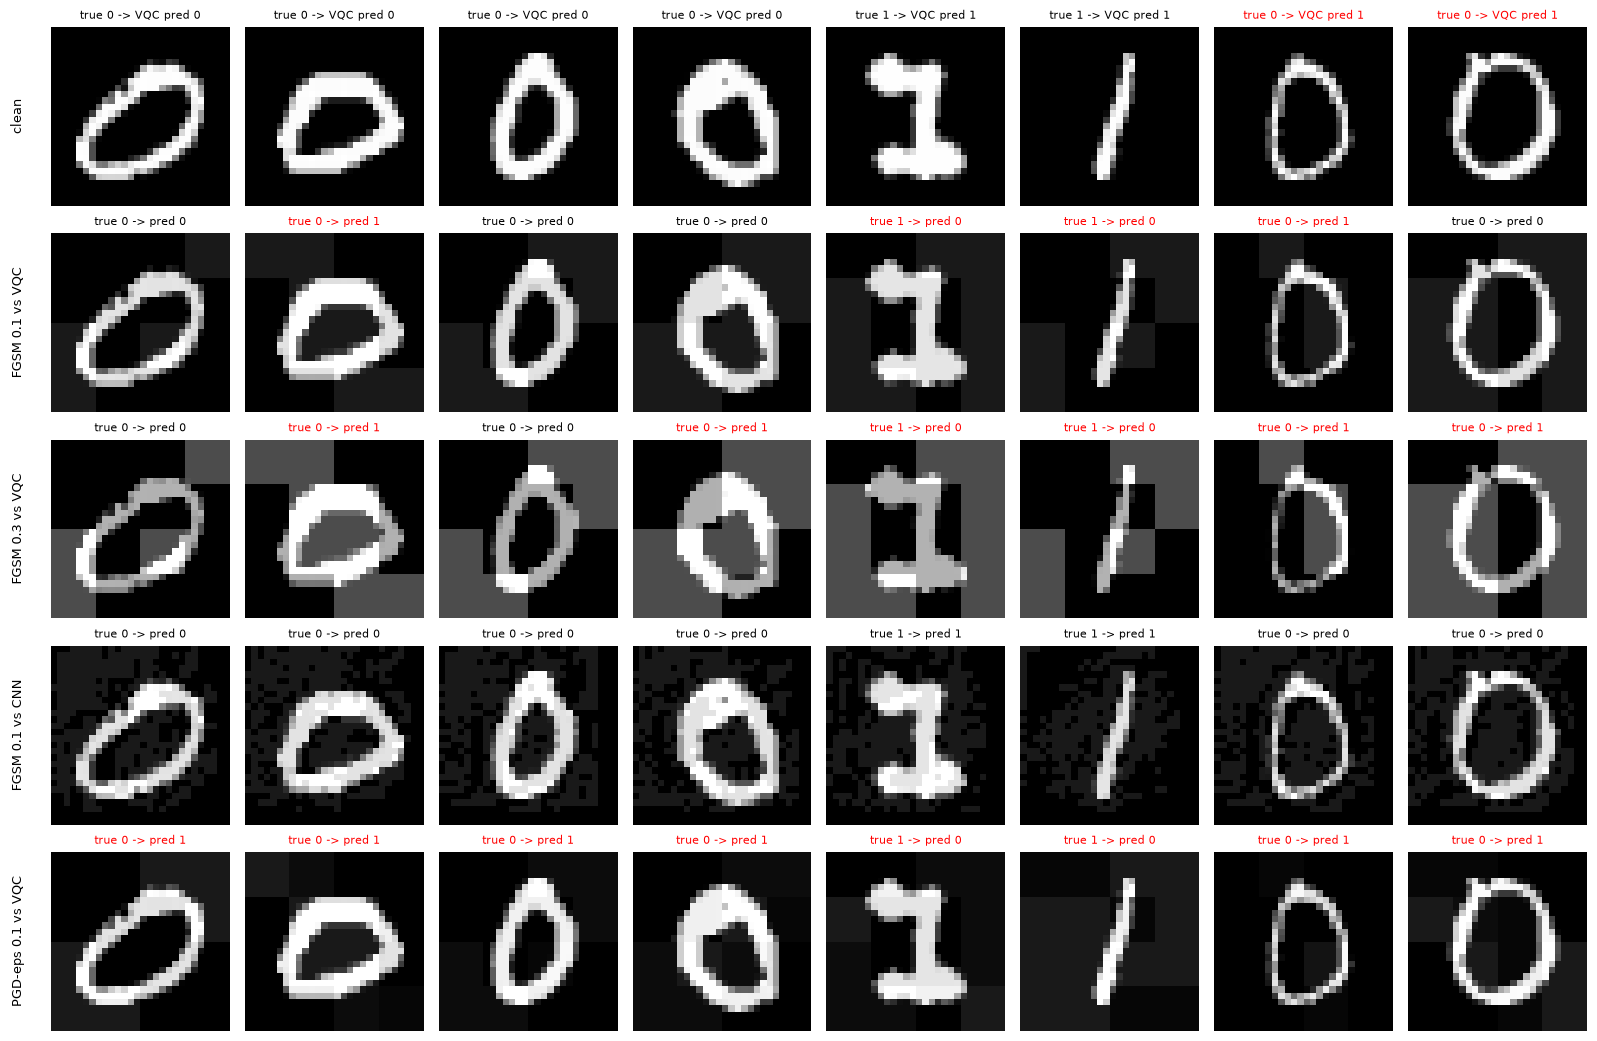

In [18]:
# Real adversarial examples (first seed): clean test images and the FGSM images against the VQC and the CNN
D, fe, xte, yte, models = KEEP["D"], KEEP["fe"], KEEP["xte"], KEEP["yte"], KEEP["models"]
names = {m.name: m for m in models}; vq, cn = names[models[0].name], names["CNN (28x28)"]
fig, axes = plt.subplots(5, 8, figsize=(16, 10.5))
rowsdef = [("clean", xte[:8], None), ("FGSM 0.1 vs VQC", KEEP["adv"][("FGSM", 0.1, vq.name)], vq), ("FGSM 0.3 vs VQC", KEEP["adv"][("FGSM", 0.3, vq.name)], vq),
           ("FGSM 0.1 vs CNN", KEEP["adv"][("FGSM", 0.1, "CNN (28x28)")], cn), ("PGD-eps 0.1 vs VQC", KEEP["adv"][("PGD-eps", 0.1, vq.name)], vq)]
for r, (ttl, X, mdl) in enumerate(rowsdef):
    pred = (vq if mdl is None else mdl).predict(X)
    for c in range(8):
        axes[r, c].imshow(X[c].reshape(28, 28).numpy(), cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
        axes[r, c].set_title(f"true {D['dte'][c]} -> {'pred ' + str(pred[c]) if mdl is not None else 'VQC pred ' + str(pred[c])}", fontsize=8, color="k" if pred[c] == yte[c] else "red")
    axes[r, 0].text(-0.15, 0.5, ttl, transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
plt.tight_layout(); plt.show()

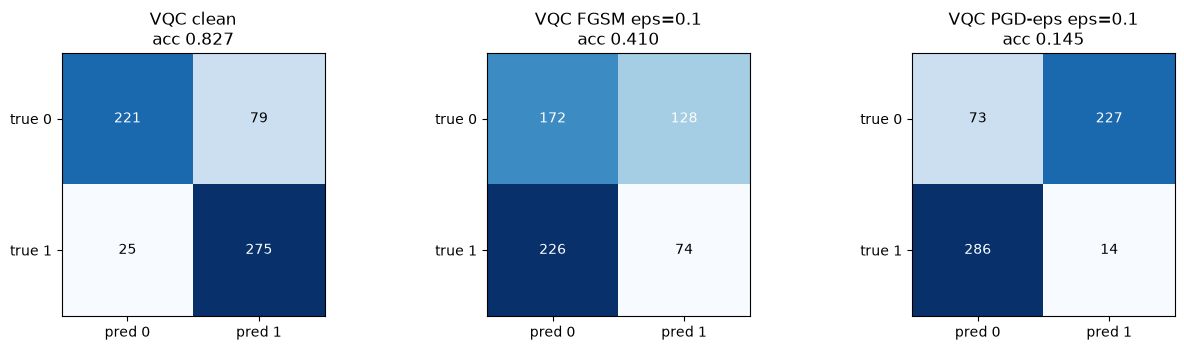

In [19]:
# Confusion matrices of the VQC for the first seed (positive class = digit 1, label 1)
vq = KEEP["models"][0]; xte, yte = KEEP["xte"], KEEP["yte"]
cases = ["clean", "FGSM eps=0.1", "PGD-eps eps=0.1"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, ttl in zip(axes, cases):
    X = xte if ttl == "clean" else attack("FGSM" if ttl.startswith("FGSM") else "PGD-eps", vq, xte, yte, 0.1)
    cm = confusion_matrix(yte, vq.predict(X), labels=[0, 1]); ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticklabels(["true 0", "true 1"])
    ax.set_title(f"VQC {ttl}\nacc {np.trace(cm) / cm.sum():.3f}")
plt.tight_layout(); plt.show()

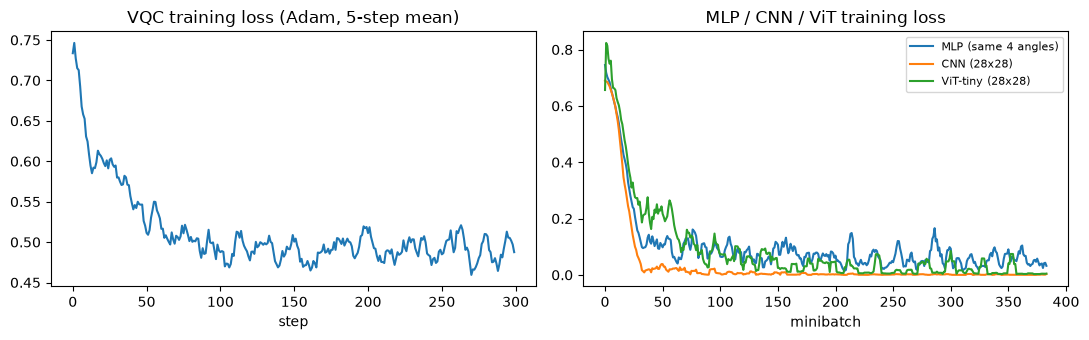

VQC input gradient: autograd vs finite difference, max relative error over the 5 largest pixels = 9.7e-09
FGSM       largest pixel change per epsilon [0.01, 0.05, 0.1, 0.2, 0.3, 0.4]: [0.01 0.05 0.1  0.2  0.3  0.4 ]
PGD-eps    largest pixel change per epsilon [0.01, 0.05, 0.1, 0.2, 0.3, 0.4]: [0.01 0.05 0.1  0.2  0.3  0.4 ]
PGD-fixed  largest pixel change per epsilon [0.01, 0.05, 0.1, 0.2, 0.3, 0.4]: [0.01 0.05 0.1  0.1  0.1  0.1 ]
  zero-gradient images (VQC (ZZ + RealAmplitudes)): 0%
  zero-gradient images (QSVM (ZZ fidelity kernel)): 0%
  zero-gradient images (SVC-RBF (same 4 angles)): 0%
  zero-gradient images (MLP (same 4 angles)): 0%
  zero-gradient images (CNN (28x28)): 0%


  zero-gradient images (ViT-tiny (28x28)): 0%


In [20]:
# Training curves of the first seed (VQC loss and neural-network losses) and sanity checks of the attack implementation
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(pd.Series(KEEP["models"][0].hist).rolling(5, min_periods=1).mean()); axes[0].set_title("VQC training loss (Adam, 5-step mean)"); axes[0].set_xlabel("step")
for m in KEEP["models"][3:]: axes[1].plot(pd.Series(m.hist).rolling(5, min_periods=1).mean(), label=m.name)
axes[1].set_title("MLP / CNN / ViT training loss"); axes[1].set_xlabel("minibatch"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# (a) autograd input gradient of the VQC vs a central finite difference on a few pixels
vq, xte, yte = KEEP["models"][0], KEEP["xte"], KEEP["yte"]
x0 = xte[:1].clone().requires_grad_(True); g, = torch.autograd.grad(vq.score(x0).sum(), x0)
pix = np.argsort(-np.abs(g[0].numpy()))[:5]; err = []
for p in pix:
    e = torch.zeros_like(xte[:1]); e[0, p] = 1e-6
    fd = ((vq.score(xte[:1] + e) - vq.score(xte[:1] - e)) / 2e-6).item(); err.append(abs(fd - g[0, p].item()) / (abs(fd) + 1e-12))
print("VQC input gradient: autograd vs finite difference, max relative error over the 5 largest pixels =", f"{max(err):.1e}")
assert max(err) < 1e-4

# (b) the perturbation really stays in the epsilon ball; PGD-fixed can never exceed 10 * 0.01 = 0.1
for kind in ATTACKS:
    reach = [float((KEEP["adv"][(kind, eps, vq.name)] - xte[:8]).abs().max()) for eps in EPS_LIST]
    print(f"{kind:10s} largest pixel change per epsilon {EPS_LIST}:", np.round(reach, 3))
    assert all(r <= e + 1e-9 for r, e in zip(reach, EPS_LIST))
# (c) gradient masking diagnostic: share of test images with an all-zero input gradient
for m in KEEP["models"]:
    gs = grad_sign(m, xte[:100], yte[:100]); print(f"  zero-gradient images ({m.name}): {(gs.abs().sum(1) == 0).float().mean().item():.0%}")

## 7. Side by side with the paper and verdicts

Rule: a numeric value is **reproduced** when our mean accuracy is within 0.02 (2 accuracy points) of the paper's; otherwise **not reached** (ours lower) or **exceeded** (ours higher) with the gap. Qualitative claims are tested with explicit criteria stated in the table. Claims that depend on something the notebook cannot do (noise, other attacks, Yocam et al.'s Table 2) are **cannot be checked**.

In [21]:
def acc(model_prefix, kind, eps):
    t = AGG[(AGG.model.str.startswith(model_prefix)) & (AGG.attack == kind) & (np.isclose(AGG.eps, eps))]; return float(t["mean"].iloc[0])
def verdict(ours, paper, tol=0.02): return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached")
VQ = "VQC"
V = []
# --- Table 1 numbers (VQC) -------------------------------------------------------------------------
for eps in EPS_LIST:
    o = acc(VQ, "FGSM", eps); V.append(dict(claim=f"Table 1 VQC FGSM, eps={eps}", paper=PAPER_FGSM[eps], notebook=round(o, 4), verdict=verdict(o, PAPER_FGSM[eps]), note=f"gap {o - PAPER_FGSM[eps]:+.3f}"))
for kind in ["PGD-eps", "PGD-fixed"]:
    for eps in EPS_LIST:
        o = acc(VQ, kind, eps); V.append(dict(claim=f"Table 1 VQC PGD, eps={eps} (ours: {kind})", paper=PAPER_PGD[eps], notebook=round(o, 4), verdict=verdict(o, PAPER_PGD[eps]), note=f"gap {o - PAPER_PGD[eps]:+.3f}"))
o = acc(VQ, "clean", 0.0); V.append(dict(claim="clean VQC accuracy (text, 5.1)", paper=PAPER_CLEAN_PGD, notebook=round(o, 4), verdict=verdict(o, PAPER_CLEAN_PGD), note=f"gap {o - PAPER_CLEAN_PGD:+.3f}"))

# --- qualitative claims ------------------------------------------------------------------------------
def curve(prefix, kind): return np.array([acc(prefix, kind, e) for e in EPS_LIST])
def lin_r2(y): return float(np.corrcoef(EPS_LIST, y)[0, 1] ** 2)
for prefix in ["VQC", "QSVM"]:
    c = curve(prefix, "FGSM"); mono = bool(np.all(np.diff(c) <= 0.01)); r2 = lin_r2(c); drop = c[0] - c[-1]
    V.append(dict(claim=f"{prefix}: FGSM accuracy declines steadily with epsilon (non-increasing within 0.01, drop eps 0.01 -> 0.4 > 0.05)", paper="steady decline", notebook=f"drop {drop:.3f}, monotone {mono}",
                  verdict="reproduced" if (mono and drop > 0.05) else "not reached", note=f"linear fit R^2 = {r2:.2f} ('near-linear' needs R^2 >= 0.9: {'yes' if r2 >= 0.9 else 'no'})"))
for prefix in ["VQC", "QSVM"]:
    for kind in ["PGD-eps", "PGD-fixed"]:
        c = curve(prefix, kind); late = c[2:]; plateau = (late.max() - late.min()) <= 0.01; early_drop = acc(prefix, "clean", 0.0) - c[2]
        V.append(dict(claim=f"{prefix}: PGD drops, then plateaus beyond eps=0.1 (range of eps>=0.1 within 0.01 and drop to eps=0.1 > 0.03) [{kind}]", paper="drop then plateau", notebook=f"range {late.max() - late.min():.3f}, drop to 0.1 = {early_drop:.3f}",
                      verdict="reproduced" if (plateau and early_drop > 0.03) else "not reached", note="plateau is forced by the attack budget in PGD-fixed" if kind == "PGD-fixed" else "no plateau expected: reach grows with eps"))
for prefix in ["VQC", "QSVM"]:
    f, p = acc(prefix, "FGSM", 0.4), acc(prefix, "PGD-eps", 0.4); V.append(dict(claim=f"{prefix}: robustness is attack-dependent (|FGSM - PGD-eps| accuracy at eps=0.4 > 0.05)", paper="attack-dependent", notebook=f"FGSM {f:.3f} vs PGD {p:.3f}", verdict="reproduced" if abs(f - p) > 0.05 else "not reached", note=""))
for prefix in ["VQC", "QSVM"]:
    q, cn = acc(prefix, "FGSM", 0.05), acc("CNN", "FGSM", 0.05)
    V.append(dict(claim=f"{prefix} keeps a higher accuracy than the CNN at FGSM eps=0.05 (Section 5.2)", paper="QNN > CNN at 0.05", notebook=f"{q:.3f} vs CNN {cn:.3f}", verdict="reproduced" if q > cn else "not reached", note=""))
for prefix in ["VQC", "QSVM"]:
    qd = acc(prefix, "clean", 0.0) - acc(prefix, "FGSM", 0.4); cd = acc("CNN", "clean", 0.0) - acc("CNN", "FGSM", 0.4)
    V.append(dict(claim=f"{prefix} loses less accuracy than the CNN over FGSM eps=0.4 (abstract: 'advantages over classical models like CNNs')", paper="QNN more robust", notebook=f"drop {qd:.3f} vs CNN {cd:.3f}", verdict="reproduced" if qd < cd - 0.02 else "not reached", note=""))
V.append(dict(claim="QNN more robust than transformers", paper="stated, no numbers", notebook=f"ViT FGSM 0.4 acc {acc('ViT', 'FGSM', 0.4):.3f}", verdict="cannot be checked", note="paper reports no transformer numbers; our own ViT numbers are in the tables"))
V.append(dict(claim="Table 2 (MNIST/EMNIST, CW+PGD: QNN 92%, CNN without defence 5%)", paper="92% / 5%", notebook="-", verdict="cannot be checked", note="copied from Yocam et al. 2024; different models, data and attacks (CW)"))
V.append(dict(claim="Noise raises vulnerability at large epsilon (5.3)", paper="stated", notebook="-", verdict="cannot be checked", note="conclusion says experiments were noiseless; not tested here"))
VERD = pd.DataFrame(V)
pd.set_option("display.max_colwidth", 120, "display.width", 250)
display(VERD)
print(VERD.verdict.value_counts().to_string())

,claim,paper,notebook,verdict,note
0,"Table 1 VQC FGSM, eps=0.01",0.9144,0.7713,not reached,gap -0.143
1,"Table 1 VQC FGSM, eps=0.05",0.8978,0.5203,not reached,gap -0.377
2,"Table 1 VQC FGSM, eps=0.1",0.8748,0.4303,not reached,gap -0.444
3,"Table 1 VQC FGSM, eps=0.2",0.8217,0.4583,not reached,gap -0.363
4,"Table 1 VQC FGSM, eps=0.3",0.76,0.5243,not reached,gap -0.236
5,"Table 1 VQC FGSM, eps=0.4",0.6931,0.4647,not reached,gap -0.228
6,"Table 1 VQC PGD, eps=0.01 (ours: PGD-eps)",0.8634,0.7687,not reached,gap -0.095
7,"Table 1 VQC PGD, eps=0.05 (ours: PGD-eps)",0.8417,0.4017,not reached,gap -0.440
8,"Table 1 VQC PGD, eps=0.1 (ours: PGD-eps)",0.8119,0.1863,not reached,gap -0.626
9,"Table 1 VQC PGD, eps=0.2 (ours: PGD-eps)",0.8119,0.182,not reached,gap -0.630


verdict
not reached          25
reproduced            6
cannot be checked     3


In [22]:
# Compact paper-vs-notebook version of Table 1 (VQC)
T1 = pd.DataFrame({"epsilon": EPS_LIST,
                   "paper FGSM": [PAPER_FGSM[e] for e in EPS_LIST], "ours FGSM": [round(acc(VQ, "FGSM", e), 4) for e in EPS_LIST],
                   "paper PGD": [PAPER_PGD[e] for e in EPS_LIST], "ours PGD-eps": [round(acc(VQ, "PGD-eps", e), 4) for e in EPS_LIST], "ours PGD-fixed": [round(acc(VQ, "PGD-fixed", e), 4) for e in EPS_LIST],
                   "ours QSVM FGSM": [round(acc("QSVM", "FGSM", e), 4) for e in EPS_LIST], "ours CNN FGSM": [round(acc("CNN", "FGSM", e), 4) for e in EPS_LIST]})
display(T1)
print(f"clean accuracy: paper {PAPER_CLEAN_PGD} | ours VQC {acc(VQ, 'clean', 0.0):.4f}, QSVM {acc('QSVM', 'clean', 0.0):.4f}, CNN {acc('CNN', 'clean', 0.0):.4f}")
print(f"total notebook time so far: {(time.time() - T0) / 60:.1f} min")

,epsilon,paper FGSM,ours FGSM,paper PGD,ours PGD-eps,ours PGD-fixed,ours QSVM FGSM,ours CNN FGSM
0,0.01,0.9144,0.7713,0.8634,0.7687,0.7703,0.9527,0.9973
1,0.05,0.8978,0.5203,0.8417,0.4017,0.3933,0.8053,0.9940
2,0.10,0.8748,0.4303,0.8119,0.1863,0.1403,0.5423,0.9890
3,0.20,0.8217,0.4583,0.8119,0.1820,0.1403,0.4673,0.9397
4,0.30,0.7600,0.5243,0.8119,0.2117,0.1403,0.4353,0.6767
5,0.40,0.6931,0.4647,0.8119,0.3007,0.1403,0.4357,0.3740


clean accuracy: paper 0.8686 | ours VQC 0.8377, QSVM 0.9697, CNN 0.9973
total notebook time so far: 39.2 min


﻿## Reading the paper critically

**What we found (5 seeds, 600 test images each, `FAST_MODE = False`).** None of the 18 numbers of Table 1 is reproduced within 2 accuracy points (the clean accuracy, 0.838 against 0.8686, is 3 points away, inside our seed spread). Our VQC loses accuracy much faster than the paper's: FGSM accuracy 0.77 / 0.52 / 0.43 / 0.46 / 0.52 / 0.46 at `epsilon` = 0.01 / 0.05 / 0.1 / 0.2 / 0.3 / 0.4 against the paper's 0.914 / 0.898 / 0.875 / 0.822 / 0.760 / 0.693, i.e. about chance from `epsilon = 0.05` on. The clean accuracy is close (0.838 +- 0.046 against 0.8686). The qualitative statements are only partly supported: attack dependence holds for the VQC, a steady decline holds for the QSVM, and a plateau beyond `epsilon = 0.1` appears only for the artificial PGD-fixed variant. The paper's claim that the quantum models are more robust than a CNN at `epsilon = 0.05` is clearly not reproduced (VQC 0.52, QSVM 0.81, CNN 0.994). Status of this reproduction: partially reproduced (everything runs; the paper's central numbers and its advantage claim are not reached).

**1. The perfectly flat PGD curve is a property of the attack settings, not of the quantum model.** Table 1 reports 0.8119 four times in a row (`epsilon` = 0.1, 0.2, 0.3, 0.4), identical to four digits. A 10-step PGD with a *fixed* step of 0.01 can never move a pixel by more than 0.1, so every `epsilon` above 0.1 produces the same adversarial images and therefore the same accuracy. This is exactly what our PGD-fixed variant shows, and it shows it for **every** model (VQC 0.140, QSVM 0.430, MLP 0.455, CNN 0.987 for all `epsilon >= 0.1`, see the figure and the check cell that prints the largest pixel change). The plateau is thus not evidence of "intrinsic resilience" or of entanglement; it only says that the attack stopped growing. The paper does not give the PGD parameters, so this is our reconstruction, but it explains the numbers with no quantum argument at all.

**2. When the attack is allowed to grow with `epsilon` (PGD-eps), the VQC is not stable.** Its accuracy falls to 0.19 at `epsilon = 0.1` (below chance, the attack flips decisions on purpose) and then *rises* again to 0.30 at `epsilon = 0.4`. A stronger attack on a larger ball can only do better if it is optimal, since the small ball is contained in the big one; a larger accuracy at larger `epsilon` therefore signals an imperfect attack (large signed steps overshoot on the oscillating `ZZFeatureMap` landscape, a mild form of gradient masking), not robustness. The same non-monotone behaviour appears for FGSM (0.43 at 0.1, 0.52 at 0.3) once the accuracy sits around 50%. Reading "accuracy under attack" as a robustness score needs a strong, well-tuned attack and ideally several restarts; the paper does not show either.

**3. Clean and perturbed accuracies do not fit together.** The paper's FGSM accuracy at `epsilon = 0.01` (0.9144) is *higher* than its clean accuracy for the PGD experiment (0.8686). Either two different trained models or test sets were used, or the numbers come from different runs; no single clean baseline is given. The "robustness score" defined in Section 3.2 cannot be computed from the paper because of this.

**4. A weak model is easy to call robust.** MNIST 0 versus 1 is nearly linearly separable: every classical model on all 784 pixels reaches 99.8% to 99.9% here, and even our four-angle models reach 97% to 99%. The paper's VQC has about 87% clean accuracy, which means a small, under-trained or badly encoded circuit. Our VQC (16 parameters, 4 qubits) is in the same weak regime (84%); its fragility (it loses about 7 points already at `epsilon = 0.01`) comes from the high-frequency `ZZFeatureMap` encoding.

**5. The comparison with the CNN is confounded by the input.** In our runs the CNN on full pixels is by far the most robust model for small and medium `epsilon` (0.989 at FGSM 0.1), but the classical models that receive the **same four angles** as the quantum models (RBF-SVM 0.49, MLP 0.46, random forest 0.50) are as fragile as the VQC (0.43) and the QSVM (0.54). Four numbers obtained by linear projection of 784 pixels are a bottleneck through which every pixel perturbation adds up (the adversarial images in the figure show blocky 7x7 patches for exactly this reason). So the robustness differences in the data come from the input representation, not from quantum versus classical computation. At `epsilon >= 0.3` the CNN collapses too (FGSM 0.38 at 0.4), and our QNNs "lose less" than the CNN only because they are already at chance level: the verdict "loses less accuracy" is a floor effect, not a quantum advantage. Whether a quantum kernel is more robust than an RBF kernel is an open question at the level of a few points (QSVM 0.54 against RBF-SVM 0.49 at FGSM 0.1, within the seed spread).

**6. The explanations are not tested.** Sections 5.2 and 5.3 attribute the behaviour to superposition, entanglement, "feature space curvature" and overparameterisation, but no experiment varies any of them (no circuit without entanglement, no depth sweep, no noise run although 5.3 speaks of simulated noise and the conclusion says "noiseless"). Table 2 is copied from Yocam et al. (2024) and concerns other models, EMNIST and CW attacks. The paper also mixes three descriptions of the quantum model (abstract: quantum kernel; Section 5: two QNN types, VQCs; conclusion: QSVM with a `ZZFeatureMap`), announces confidence intervals and variance analysis without reporting them, and uses no seed or test-set size.

**7. Practical caveats of this notebook.** The circuit, reduction to four qubits, optimiser, attack norm and PGD parameters are our choices (listed in the table at the top); a different encoding (e.g. amplitude encoding of 64 pixels on 6 qubits) could move the quantum curves a lot. Attacks are white-box on exact simulators; an attacker on a real device would only have noisy, shot-based gradients (the other notebooks of this folder study that). The random forest is attacked by transfer only, so its numbers are an upper bound on its robustness.

﻿## Exercises

1. **A better attack.** Replace PGD with 50 steps, a random start and 5 restarts (keep the best restart per image) for the VQC. Does accuracy become non-increasing in `epsilon`? Compute, for each model, the share of `epsilon` pairs `(small, large)` for which accuracy *increases* with `epsilon`: it is a simple diagnostic of how far an attack is from optimal.
2. **Reproduce the paper's plateau on purpose.** Change `PGD_STEPS` and `PGD_ALPHA_FIXED` (for example 20 steps of 0.02) and predict, before running, from which `epsilon` the curve becomes flat. Then check that the plateau moves exactly there for the CNN as well.
3. **Adversarial training (paper Section 4.2, no results given).** Train the VQC, the MLP and the CNN on a mixture of clean images and FGSM images with `epsilon = 0.1` (re-crafted every epoch against the current model) and rerun the attacks. Does adversarial training help the quantum model more or less than the CNN?
4. **Entanglement and depth.** Rebuild the VQC with `entanglement="linear"` replaced by no CNOTs in `real_amplitudes` and `zz_feature_map(..., reps=1)`, or increase `ANSATZ_REPS`. Does the robustness curve change? This is the experiment that Sections 5.2/5.3 of the paper would need to support their explanation.
5. **Quantum noise.** Run the trained VQC through a noisy Qiskit Aer simulator (for example a `qiskit_ibm_runtime.fake_provider` backend) with a finite number of shots and attack the *noisy* model with the parameter-shift or finite-difference gradient estimated from shots. Does shot noise weaken the attacker, as the other notebooks of this folder suggest?